In [1]:

import os
import time
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATASET_ROOT = Path(
    "/kaggle/input/datasets/aditya000001/"
    "group-16-caltech-101/Group_16"
)

TRAIN_DIR = DATASET_ROOT / "train"
VAL_DIR = DATASET_ROOT / "val"
TEST_DIR = DATASET_ROOT / "test"

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Dataset root exists:", DATASET_ROOT.exists())
print("Output directory:", OUTPUT_DIR)


PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Dataset root exists: True
Output directory: /kaggle/working/part_b_q1_results


In [4]:

for split_name, split_dir in [
    ("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR),
]:
    print(f"\n{split_name}: {split_dir}")
    print("Exists:", split_dir.is_dir())

    if split_dir.is_dir():
        for class_dir in sorted(split_dir.iterdir()):
            if class_dir.is_dir():
                image_count = sum(
                    p.suffix.lower() in {
                        ".jpg", ".jpeg", ".png", ".bmp"
                    }
                    for p in class_dir.iterdir()
                    if p.is_file()
                )
                print(f"  {class_dir.name}: {image_count} images")



Train: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train
Exists: True
  Leopards: 50 images
  buddha: 50 images
  butterfly: 50 images
  kangaroo: 50 images
  starfish: 50 images

Validation: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/val
Exists: True
  Leopards: 10 images
  buddha: 10 images
  butterfly: 10 images
  kangaroo: 10 images
  starfish: 10 images

Test: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/test
Exists: True
  Leopards: 20 images
  buddha: 20 images
  butterfly: 20 images
  kangaroo: 20 images
  starfish: 20 images


In [10]:

# IMAGE_SIZE = 224
# BATCH_SIZE = 16

# transform = transforms.Compose([
#     transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
#     transforms.Lambda(lambda image: image.convert("RGB")),
#     transforms.ToTensor(),
# ])

# train_dataset = datasets.ImageFolder(
#     TRAIN_DIR, transform=transform
# )
# val_dataset = datasets.ImageFolder(
#     VAL_DIR, transform=transform
# )
# test_dataset = datasets.ImageFolder(
#     TEST_DIR, transform=transform
# )

# class_names = train_dataset.classes
# num_classes = len(class_names)

# assert val_dataset.classes == class_names
# assert test_dataset.classes == class_names
# assert num_classes == 5

# train_loader = DataLoader(
#     train_dataset, batch_size=BATCH_SIZE,
#     shuffle=True, num_workers=2, pin_memory=True
# )
# val_loader = DataLoader(
#     val_dataset, batch_size=BATCH_SIZE,
#     shuffle=False, num_workers=2, pin_memory=True
# )
# test_loader = DataLoader(
#     test_dataset, batch_size=BATCH_SIZE,
#     shuffle=False, num_workers=2, pin_memory=True
# )

# print("Class-to-index mapping:", train_dataset.class_to_idx)
# print("Training images:", len(train_dataset))
# print("Validation images:", len(val_dataset))
# print("Test images:", len(test_dataset))

# images, labels = next(iter(train_loader))
# print("Image batch shape:", images.shape)
# print("Label batch shape:", labels.shape)
# print("Pixel range:", images.min().item(), images.max().item())

# assert images.shape[1:] == (3, 224, 224)



from torchvision import transforms, datasets
from torch.utils.data import DataLoader

IMAGE_SIZE = 224
BATCH_SIZE = 16

# 1. Pipeline for Training Data (with Data Augmentation)
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=10),                   # Randomly rotate within -10 to +10 degrees
    # transforms.ColorJitter(brightness=0.2, contrast=0.2),    # Slight random shifts in lighting
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor()
])

# 2. Pipeline for Validation & Test Data (Deterministic, NO Augmentation)
val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor()
])

# 3. Apply the specific transforms to each dataset
train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
val_dataset = datasets.ImageFolder(
    VAL_DIR, transform=val_test_transform
)
test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=val_test_transform
)

class_names = train_dataset.classes
num_classes = len(class_names)

assert val_dataset.classes == class_names
assert test_dataset.classes == class_names
assert num_classes == 5

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print("Class-to-index mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())

assert images.shape[1:] == (3, 224, 224)



Class-to-index mapping: {'Leopards': 0, 'buddha': 1, 'butterfly': 2, 'kangaroo': 3, 'starfish': 4}
Training images: 250
Validation images: 50
Test images: 100
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Pixel range: -2.1179039478302 2.640000104904175


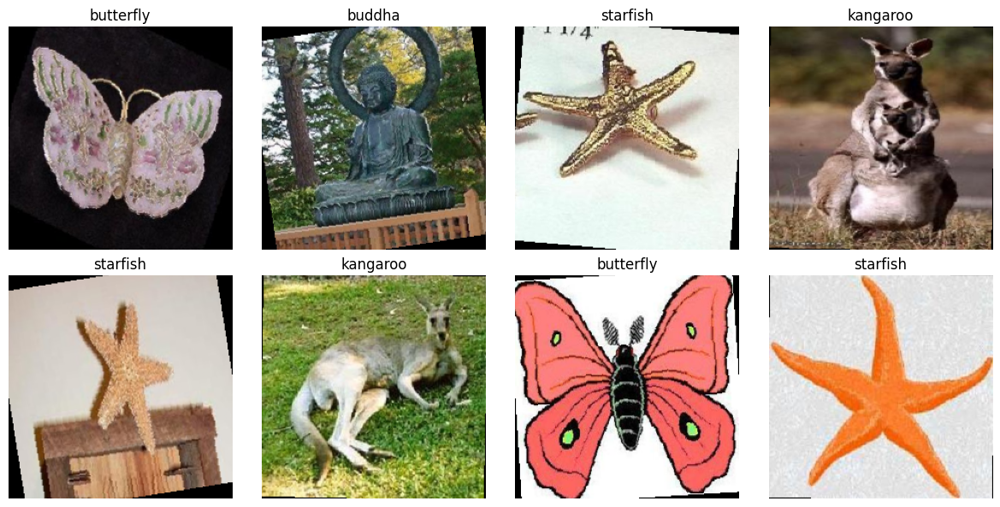

In [42]:

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [43]:

class CNNArchitecture1(nn.Module):
    """Two convolutional layers."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 10 * 10, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNNArchitecture2(nn.Module):
    """Three convolutional layers."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 3 * 3, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNNArchitecture3(nn.Module):
    """Four convolutional layers; no pool after Conv3."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 2 * 2, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


models = {
    "Architecture-1": CNNArchitecture1(),
    "Architecture-2": CNNArchitecture2(),
    "Architecture-3": CNNArchitecture3(),
}

# Verify every layer's output dimensions.
dummy = torch.zeros(1, 3, 224, 224)

for name, model in models.items():
    print(f"\n{name}")
    x = dummy
    for layer in model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:15s}: {tuple(x.shape)}")

    logits = model(dummy)
    print("Logits shape:", tuple(logits.shape))
    assert logits.shape == (1, 5)



Architecture-1
Conv2d         : (1, 8, 54, 54)
ReLU           : (1, 8, 54, 54)
MaxPool2d      : (1, 8, 26, 26)
Conv2d         : (1, 16, 22, 22)
ReLU           : (1, 16, 22, 22)
MaxPool2d      : (1, 16, 10, 10)
Logits shape: (1, 5)

Architecture-2
Conv2d         : (1, 8, 54, 54)
ReLU           : (1, 8, 54, 54)
MaxPool2d      : (1, 8, 26, 26)
Conv2d         : (1, 16, 22, 22)
ReLU           : (1, 16, 22, 22)
MaxPool2d      : (1, 16, 10, 10)
Conv2d         : (1, 32, 8, 8)
ReLU           : (1, 32, 8, 8)
MaxPool2d      : (1, 32, 3, 3)
Logits shape: (1, 5)

Architecture-3
Conv2d         : (1, 8, 54, 54)
ReLU           : (1, 8, 54, 54)
MaxPool2d      : (1, 8, 26, 26)
Conv2d         : (1, 16, 22, 22)
ReLU           : (1, 16, 22, 22)
MaxPool2d      : (1, 16, 10, 10)
Conv2d         : (1, 32, 8, 8)
ReLU           : (1, 32, 8, 8)
Conv2d         : (1, 64, 6, 6)
ReLU           : (1, 64, 6, 6)
MaxPool2d      : (1, 64, 2, 2)
Logits shape: (1, 5)


In [44]:

import copy
import time
import json

EPOCHS = 100
LEARNING_RATE = 1e-3
PATIENCE = 10

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.cpu().numpy().tolist())
        all_pred.extend(predictions.cpu().numpy().tolist())

    mean_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_true, all_pred)

    return mean_loss, accuracy, all_true, all_pred


def train_architecture(name, model):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }

    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc, _, _ = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc, _, _ = run_epoch(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if epoch %5 ==0:
            print(
                f"{name} | Epoch {epoch:02d}/{EPOCHS} | "
                f"Train loss={train_loss:.4f}, "
                f"Train acc={train_acc:.4f} | "
                f"Val loss={val_loss:.4f}, "
                f"Val acc={val_acc:.4f}"
            )

        improved = (
            val_acc > best_val_accuracy
            or (
                val_acc == best_val_accuracy
                and val_loss < best_val_loss
            )
        )
        
        if improved:
            best_val_accuracy = val_acc
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    model.load_state_dict(best_state)

    checkpoint_path = OUTPUT_DIR / f"{name.lower().replace('-', '_')}_patience_10_improved.pt"
    torch.save(model.state_dict(), checkpoint_path)

    elapsed = (time.time() - start) / 60

    print(
        f"\n{name}: best epoch={best_epoch}, "
        f"best validation loss={best_val_loss:.4f}, "
        f"time={elapsed:.2f} minutes\n"
    )

    return model, history, best_epoch


trained_models = {}
histories = {}
best_epochs = {}

for name, initial_model in models.items():
    # Start each architecture from fresh initialization.
    model, history, best_epoch = train_architecture(
        name, initial_model
    )
    trained_models[name] = model
    histories[name] = history
    best_epochs[name] = best_epoch

print("All architecture training runs finished.")


Architecture-1 | Epoch 05/100 | Train loss=1.3972, Train acc=0.4480 | Val loss=1.3797, Val acc=0.3600
Architecture-1 | Epoch 10/100 | Train loss=0.7077, Train acc=0.7320 | Val loss=1.4312, Val acc=0.5200
Architecture-1 | Epoch 15/100 | Train loss=0.4332, Train acc=0.8680 | Val loss=0.9627, Val acc=0.6800
Architecture-1 | Epoch 20/100 | Train loss=0.1722, Train acc=0.9640 | Val loss=1.1541, Val acc=0.6800
Architecture-1 | Epoch 25/100 | Train loss=0.0875, Train acc=0.9720 | Val loss=1.3741, Val acc=0.6800
Architecture-1 | Epoch 30/100 | Train loss=0.2709, Train acc=0.8920 | Val loss=1.1559, Val acc=0.6000
Architecture-1 | Epoch 35/100 | Train loss=0.0374, Train acc=0.9920 | Val loss=1.2998, Val acc=0.7600
Architecture-1 | Epoch 40/100 | Train loss=0.0165, Train acc=1.0000 | Val loss=1.5795, Val acc=0.6800
Architecture-1 | Epoch 45/100 | Train loss=0.0136, Train acc=0.9960 | Val loss=1.4000, Val acc=0.7400
Early stopping at epoch 49.

Architecture-1: best epoch=39, best validation loss=1

,Architecture,Best epoch,Training accuracy (%),Validation accuracy (%),Training loss,Validation loss
0,Architecture-1,39,100.0,78.0,0.0169,1.4433
1,Architecture-2,17,81.6,64.0,0.5577,1.4814
2,Architecture-3,26,65.6,60.0,0.8528,1.1822


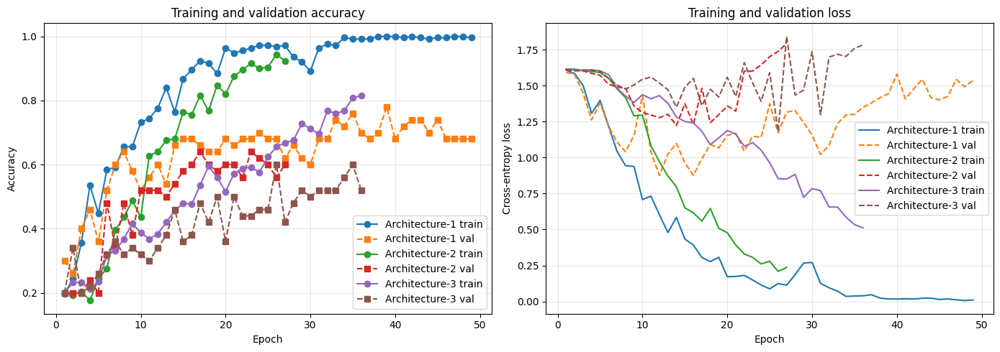

In [45]:

comparison_rows = []

for name, history in histories.items():
    best_index = best_epochs[name] - 1

    comparison_rows.append({
        "Architecture": name,
        "Best epoch": best_epochs[name],
        "Training accuracy (%)":
            100 * history["train_accuracy"][best_index],
        "Validation accuracy (%)":
            100 * history["val_accuracy"][best_index],
        "Training loss": history["train_loss"][best_index],
        "Validation loss": history["val_loss"][best_index],
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "architecture_comparison_new_pateince_10_improved.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():
    epochs = range(1, len(history["train_accuracy"]) + 1)

    axes[0].plot(
        epochs, history["train_accuracy"],
        marker="o", label=name + " train"
    )
    axes[0].plot(
        epochs, history["val_accuracy"],
        marker="s", linestyle="--", label=name + " val"
    )

    axes[1].plot(
        epochs, history["train_loss"],
        label=name + " train"
    )
    axes[1].plot(
        epochs, history["val_loss"],
        linestyle="--", label=name + " val"
    )

axes[0].set_title("Training and validation accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_new_pateince_10_improved.png", dpi=200)
plt.show()


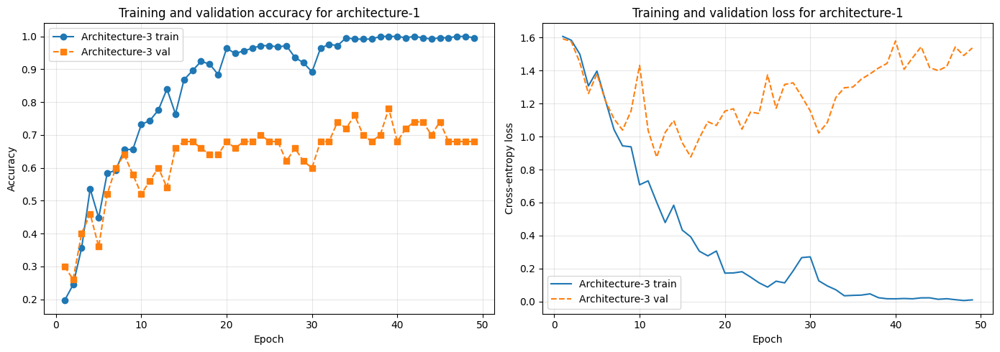

In [46]:

# comparison_rows = []

# for name, history in histories.items():
#     best_index = best_epochs[name] - 1

#     comparison_rows.append({
#         "Architecture": name,
#         "Best epoch": best_epochs[name],
#         "Training accuracy (%)":
#             100 * history["train_accuracy"][best_index],
#         "Validation accuracy (%)":
#             100 * history["val_accuracy"][best_index],
#         "Training loss": history["train_loss"][best_index],
#         "Validation loss": history["val_loss"][best_index],
#     })

# comparison_df = pd.DataFrame(comparison_rows)
# display(comparison_df.round(4))

# comparison_df.to_csv(
#     OUTPUT_DIR / "architecture_comparison.csv", index=False
# )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for name, history in histories.items():
#     epochs = range(1, len(history["train_accuracy"]) + 1)

#     axes[0].plot(
#         epochs, history["train_accuracy"],
#         marker="o", label=name + " train"
#     )
#     axes[0].plot(
#         epochs, history["val_accuracy"],
#         marker="s", linestyle="--", label=name + " val"
#     )

#     axes[1].plot(
#         epochs, history["train_loss"],
#         label=name + " train"
#     )
#     axes[1].plot(
#         epochs, history["val_loss"],
#         linestyle="--", label=name + " val"
#     )

history = histories["Architecture-1"]
epochs = range(1, len(history["train_accuracy"]) + 1)
axes[0].plot(
    epochs, history["train_accuracy"],
    marker="o", label=name + " train"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", linestyle="--", label=name + " val"
)

axes[1].plot(
    epochs, history["train_loss"],
    label=name + " train"
)
axes[1].plot(
    epochs, history["val_loss"],
    linestyle="--", label=name + " val"
)

axes[0].set_title("Training and validation accuracy for architecture-1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss for architecture-1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_architecture_1_new_pateince_10_improved.png", dpi=200)
plt.show()


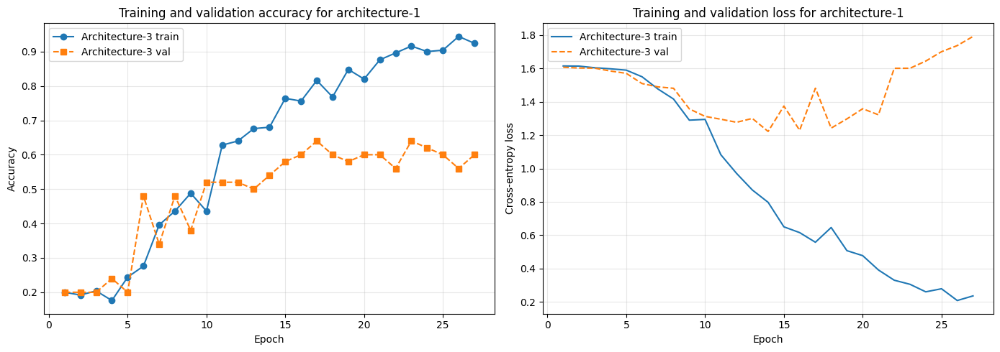

In [47]:

# comparison_rows = []

# for name, history in histories.items():
#     best_index = best_epochs[name] - 1

#     comparison_rows.append({
#         "Architecture": name,
#         "Best epoch": best_epochs[name],
#         "Training accuracy (%)":
#             100 * history["train_accuracy"][best_index],
#         "Validation accuracy (%)":
#             100 * history["val_accuracy"][best_index],
#         "Training loss": history["train_loss"][best_index],
#         "Validation loss": history["val_loss"][best_index],
#     })

# comparison_df = pd.DataFrame(comparison_rows)
# display(comparison_df.round(4))

# comparison_df.to_csv(
#     OUTPUT_DIR / "architecture_comparison.csv", index=False
# )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for name, history in histories.items():
#     epochs = range(1, len(history["train_accuracy"]) + 1)

#     axes[0].plot(
#         epochs, history["train_accuracy"],
#         marker="o", label=name + " train"
#     )
#     axes[0].plot(
#         epochs, history["val_accuracy"],
#         marker="s", linestyle="--", label=name + " val"
#     )

#     axes[1].plot(
#         epochs, history["train_loss"],
#         label=name + " train"
#     )
#     axes[1].plot(
#         epochs, history["val_loss"],
#         linestyle="--", label=name + " val"
#     )

history = histories["Architecture-2"]
epochs = range(1, len(history["train_accuracy"]) + 1)
axes[0].plot(
    epochs, history["train_accuracy"],
    marker="o", label=name + " train"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", linestyle="--", label=name + " val"
)

axes[1].plot(
    epochs, history["train_loss"],
    label=name + " train"
)
axes[1].plot(
    epochs, history["val_loss"],
    linestyle="--", label=name + " val"
)

axes[0].set_title("Training and validation accuracy for architecture-1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss for architecture-1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_architecture_2_new_pateince_10_improved.png", dpi=200)
plt.show()


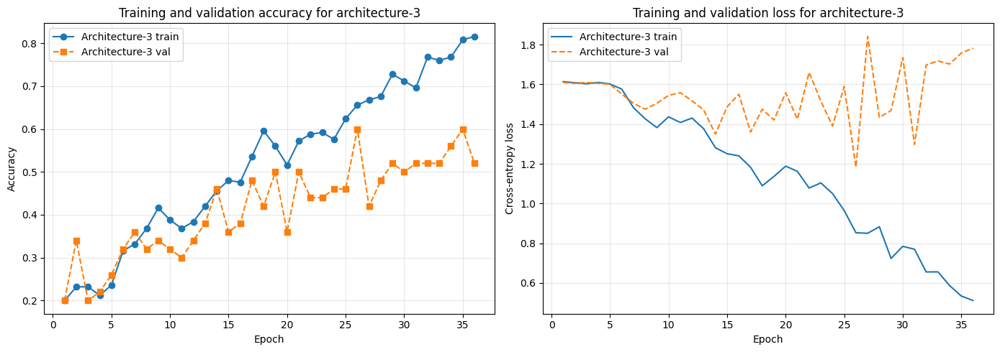

In [48]:

# comparison_rows = []

# for name, history in histories.items():
#     best_index = best_epochs[name] - 1

#     comparison_rows.append({
#         "Architecture": name,
#         "Best epoch": best_epochs[name],
#         "Training accuracy (%)":
#             100 * history["train_accuracy"][best_index],
#         "Validation accuracy (%)":
#             100 * history["val_accuracy"][best_index],
#         "Training loss": history["train_loss"][best_index],
#         "Validation loss": history["val_loss"][best_index],
#     })

# comparison_df = pd.DataFrame(comparison_rows)
# display(comparison_df.round(4))

# comparison_df.to_csv(
#     OUTPUT_DIR / "architecture_comparison.csv", index=False
# )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for name, history in histories.items():
#     epochs = range(1, len(history["train_accuracy"]) + 1)

#     axes[0].plot(
#         epochs, history["train_accuracy"],
#         marker="o", label=name + " train"
#     )
#     axes[0].plot(
#         epochs, history["val_accuracy"],
#         marker="s", linestyle="--", label=name + " val"
#     )

#     axes[1].plot(
#         epochs, history["train_loss"],
#         label=name + " train"
#     )
#     axes[1].plot(
#         epochs, history["val_loss"],
#         linestyle="--", label=name + " val"
#     )

history = histories["Architecture-3"]
epochs = range(1, len(history["train_accuracy"]) + 1)
axes[0].plot(
    epochs, history["train_accuracy"],
    marker="o", label=name + " train"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", linestyle="--", label=name + " val"
)

axes[1].plot(
    epochs, history["train_loss"],
    label=name + " train"
)
axes[1].plot(
    epochs, history["val_loss"],
    linestyle="--", label=name + " val"
)

axes[0].set_title("Training and validation accuracy for architecture-3")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss for architecture-3")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_architecture_3_new_pateince_10_improved.png", dpi=200)
plt.show()


 # **With dropout training**

In [22]:

class CNNArchitecture1(nn.Module):
    """Two convolutional layers."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 10 * 10, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNNArchitecture2(nn.Module):
    """Three convolutional layers."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNNArchitecture3(nn.Module):
    """Four convolutional layers; no pool after Conv3."""
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


models = {
    "Architecture-1": CNNArchitecture1(),
    "Architecture-2": CNNArchitecture2(),
    "Architecture-3": CNNArchitecture3(),
}

# Verify every layer's output dimensions.
dummy = torch.zeros(1, 3, 224, 224)

for name, model in models.items():
    print(f"\n{name}")
    x = dummy
    for layer in model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:15s}: {tuple(x.shape)}")

    logits = model(dummy)
    print("Logits shape:", tuple(logits.shape))
    assert logits.shape == (1, 5)



Architecture-1
Conv2d         : (1, 8, 54, 54)
ReLU           : (1, 8, 54, 54)
MaxPool2d      : (1, 8, 26, 26)
Conv2d         : (1, 16, 22, 22)
ReLU           : (1, 16, 22, 22)
MaxPool2d      : (1, 16, 10, 10)
Logits shape: (1, 5)

Architecture-2
Conv2d         : (1, 8, 54, 54)
ReLU           : (1, 8, 54, 54)
MaxPool2d      : (1, 8, 26, 26)
Conv2d         : (1, 16, 22, 22)
ReLU           : (1, 16, 22, 22)
MaxPool2d      : (1, 16, 10, 10)
Conv2d         : (1, 32, 8, 8)
ReLU           : (1, 32, 8, 8)
MaxPool2d      : (1, 32, 3, 3)
Logits shape: (1, 5)

Architecture-3
Conv2d         : (1, 8, 54, 54)
ReLU           : (1, 8, 54, 54)
MaxPool2d      : (1, 8, 26, 26)
Conv2d         : (1, 16, 22, 22)
ReLU           : (1, 16, 22, 22)
MaxPool2d      : (1, 16, 10, 10)
Conv2d         : (1, 32, 8, 8)
ReLU           : (1, 32, 8, 8)
Conv2d         : (1, 64, 6, 6)
ReLU           : (1, 64, 6, 6)
MaxPool2d      : (1, 64, 2, 2)
Logits shape: (1, 5)


In [50]:

import copy
import time
import json

EPOCHS = 100
LEARNING_RATE = 1e-3
PATIENCE = 10

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.cpu().numpy().tolist())
        all_pred.extend(predictions.cpu().numpy().tolist())

    mean_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_true, all_pred)

    return mean_loss, accuracy, all_true, all_pred


def train_architecture(name, model):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }

    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc, _, _ = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc, _, _ = run_epoch(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if epoch %5 ==0:
            print(
                f"{name} | Epoch {epoch:02d}/{EPOCHS} | "
                f"Train loss={train_loss:.4f}, "
                f"Train acc={train_acc:.4f} | "
                f"Val loss={val_loss:.4f}, "
                f"Val acc={val_acc:.4f}"
            )

        improved = (
            val_acc > best_val_accuracy
            or (
                val_acc == best_val_accuracy
                and val_loss < best_val_loss
            )
        )
        
        if improved:
            best_val_accuracy = val_acc
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    model.load_state_dict(best_state)

    checkpoint_path = OUTPUT_DIR / f"{name.lower().replace('-', '_')}_with_dropout.pt"
    torch.save(model.state_dict(), checkpoint_path)

    elapsed = (time.time() - start) / 60

    print(
        f"\n{name}: best epoch={best_epoch}, "
        f"best validation loss={best_val_loss:.4f}, "
        f"time={elapsed:.2f} minutes\n"
    )

    return model, history, best_epoch


trained_models = {}
histories = {}
best_epochs = {}

for name, initial_model in models.items():
    # Start each architecture from fresh initialization.
    model, history, best_epoch = train_architecture(
        name, initial_model
    )
    trained_models[name] = model
    histories[name] = history
    best_epochs[name] = best_epoch

print("All architecture training runs finished.")


Architecture-1 | Epoch 05/100 | Train loss=1.4949, Train acc=0.3240 | Val loss=1.4529, Val acc=0.4200
Architecture-1 | Epoch 10/100 | Train loss=0.8509, Train acc=0.6800 | Val loss=1.2672, Val acc=0.5400
Architecture-1 | Epoch 15/100 | Train loss=0.5013, Train acc=0.8240 | Val loss=1.7391, Val acc=0.5000
Architecture-1 | Epoch 20/100 | Train loss=0.3882, Train acc=0.8800 | Val loss=1.7411, Val acc=0.5600
Architecture-1 | Epoch 25/100 | Train loss=0.2532, Train acc=0.9040 | Val loss=2.0459, Val acc=0.5800
Architecture-1 | Epoch 30/100 | Train loss=0.2363, Train acc=0.9080 | Val loss=2.2897, Val acc=0.4600
Early stopping at epoch 31.

Architecture-1: best epoch=21, best validation loss=1.8959, time=0.46 minutes

Architecture-2 | Epoch 05/100 | Train loss=1.5752, Train acc=0.2920 | Val loss=1.5688, Val acc=0.2600
Architecture-2 | Epoch 10/100 | Train loss=1.4287, Train acc=0.3760 | Val loss=1.5234, Val acc=0.3600
Architecture-2 | Epoch 15/100 | Train loss=1.3745, Train acc=0.4080 | Val lo

,Architecture,Best epoch,Training accuracy (%),Validation accuracy (%),Training loss,Validation loss
0,Architecture-1,21,87.6,62.0,0.3458,1.8959
1,Architecture-2,22,56.0,64.0,1.1059,1.1649
2,Architecture-3,37,80.0,70.0,0.5459,1.1453


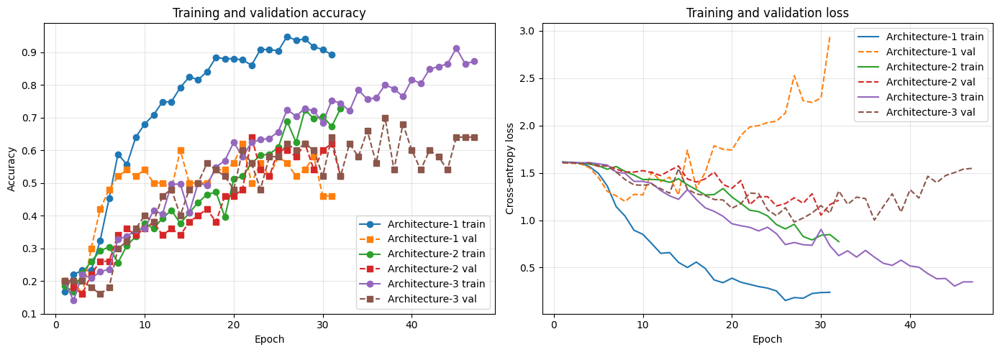

In [51]:

comparison_rows = []

for name, history in histories.items():
    best_index = best_epochs[name] - 1

    comparison_rows.append({
        "Architecture": name,
        "Best epoch": best_epochs[name],
        "Training accuracy (%)":
            100 * history["train_accuracy"][best_index],
        "Validation accuracy (%)":
            100 * history["val_accuracy"][best_index],
        "Training loss": history["train_loss"][best_index],
        "Validation loss": history["val_loss"][best_index],
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "architecture_comparison_with_dropout.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():
    epochs = range(1, len(history["train_accuracy"]) + 1)

    axes[0].plot(
        epochs, history["train_accuracy"],
        marker="o", label=name + " train"
    )
    axes[0].plot(
        epochs, history["val_accuracy"],
        marker="s", linestyle="--", label=name + " val"
    )

    axes[1].plot(
        epochs, history["train_loss"],
        label=name + " train"
    )
    axes[1].plot(
        epochs, history["val_loss"],
        linestyle="--", label=name + " val"
    )

axes[0].set_title("Training and validation accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_with_dropout.png", dpi=200)
plt.show()


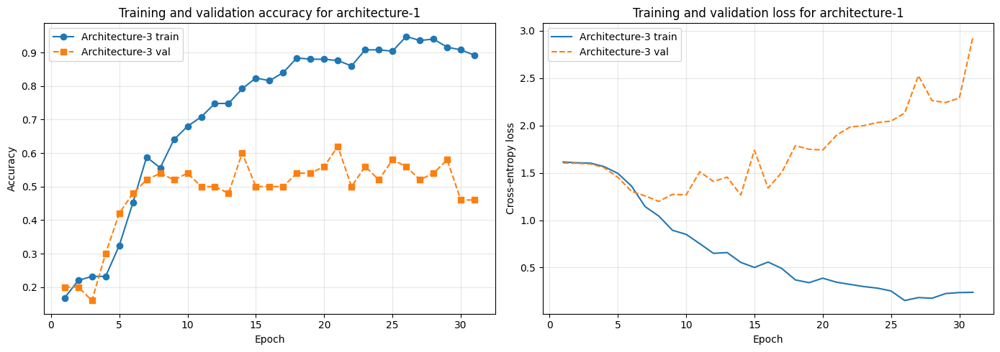

In [52]:

# comparison_rows = []

# for name, history in histories.items():
#     best_index = best_epochs[name] - 1

#     comparison_rows.append({
#         "Architecture": name,
#         "Best epoch": best_epochs[name],
#         "Training accuracy (%)":
#             100 * history["train_accuracy"][best_index],
#         "Validation accuracy (%)":
#             100 * history["val_accuracy"][best_index],
#         "Training loss": history["train_loss"][best_index],
#         "Validation loss": history["val_loss"][best_index],
#     })

# comparison_df = pd.DataFrame(comparison_rows)
# display(comparison_df.round(4))

# comparison_df.to_csv(
#     OUTPUT_DIR / "architecture_comparison.csv", index=False
# )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for name, history in histories.items():
#     epochs = range(1, len(history["train_accuracy"]) + 1)

#     axes[0].plot(
#         epochs, history["train_accuracy"],
#         marker="o", label=name + " train"
#     )
#     axes[0].plot(
#         epochs, history["val_accuracy"],
#         marker="s", linestyle="--", label=name + " val"
#     )

#     axes[1].plot(
#         epochs, history["train_loss"],
#         label=name + " train"
#     )
#     axes[1].plot(
#         epochs, history["val_loss"],
#         linestyle="--", label=name + " val"
#     )

history = histories["Architecture-1"]
epochs = range(1, len(history["train_accuracy"]) + 1)
axes[0].plot(
    epochs, history["train_accuracy"],
    marker="o", label=name + " train"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", linestyle="--", label=name + " val"
)

axes[1].plot(
    epochs, history["train_loss"],
    label=name + " train"
)
axes[1].plot(
    epochs, history["val_loss"],
    linestyle="--", label=name + " val"
)

axes[0].set_title("Training and validation accuracy for architecture-1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss for architecture-1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_architecture_1_woth_dropout.png", dpi=200)
plt.show()


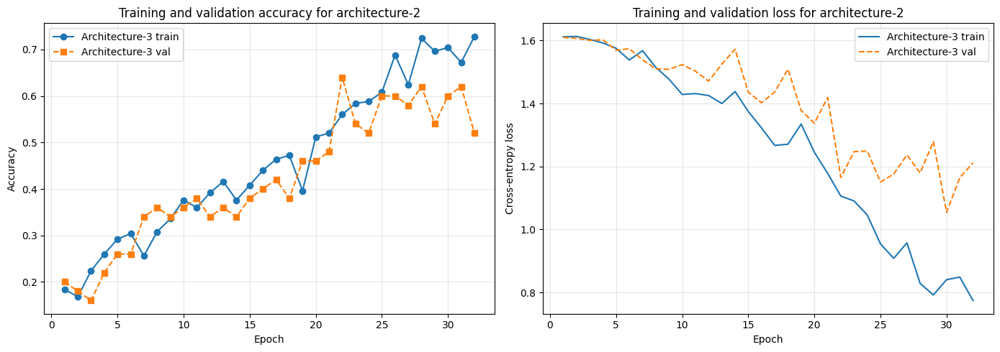

In [54]:

# comparison_rows = []

# for name, history in histories.items():
#     best_index = best_epochs[name] - 1

#     comparison_rows.append({
#         "Architecture": name,
#         "Best epoch": best_epochs[name],
#         "Training accuracy (%)":
#             100 * history["train_accuracy"][best_index],
#         "Validation accuracy (%)":
#             100 * history["val_accuracy"][best_index],
#         "Training loss": history["train_loss"][best_index],
#         "Validation loss": history["val_loss"][best_index],
#     })

# comparison_df = pd.DataFrame(comparison_rows)
# display(comparison_df.round(4))

# comparison_df.to_csv(
#     OUTPUT_DIR / "architecture_comparison.csv", index=False
# )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for name, history in histories.items():
#     epochs = range(1, len(history["train_accuracy"]) + 1)

#     axes[0].plot(
#         epochs, history["train_accuracy"],
#         marker="o", label=name + " train"
#     )
#     axes[0].plot(
#         epochs, history["val_accuracy"],
#         marker="s", linestyle="--", label=name + " val"
#     )

#     axes[1].plot(
#         epochs, history["train_loss"],
#         label=name + " train"
#     )
#     axes[1].plot(
#         epochs, history["val_loss"],
#         linestyle="--", label=name + " val"
#     )

history = histories["Architecture-2"]
epochs = range(1, len(history["train_accuracy"]) + 1)
axes[0].plot(
    epochs, history["train_accuracy"],
    marker="o", label=name + " train"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", linestyle="--", label=name + " val"
)

axes[1].plot(
    epochs, history["train_loss"],
    label=name + " train"
)
axes[1].plot(
    epochs, history["val_loss"],
    linestyle="--", label=name + " val"
)

axes[0].set_title("Training and validation accuracy for architecture-2")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss for architecture-2")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_architecture_2_woth_dropout.png", dpi=200)
plt.show()


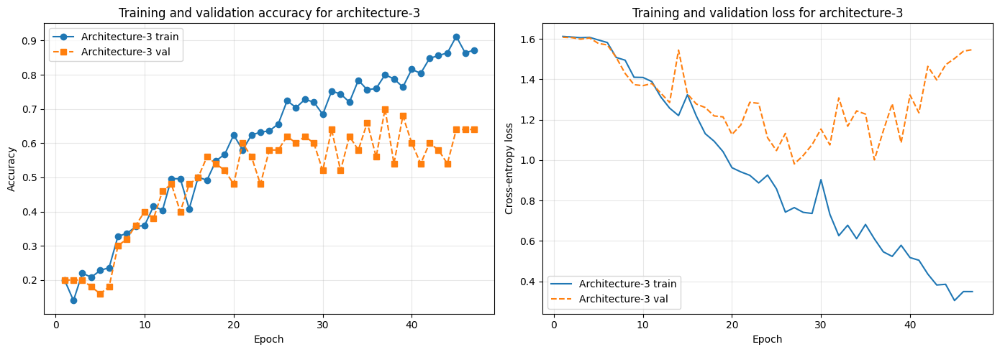

In [55]:

# comparison_rows = []

# for name, history in histories.items():
#     best_index = best_epochs[name] - 1

#     comparison_rows.append({
#         "Architecture": name,
#         "Best epoch": best_epochs[name],
#         "Training accuracy (%)":
#             100 * history["train_accuracy"][best_index],
#         "Validation accuracy (%)":
#             100 * history["val_accuracy"][best_index],
#         "Training loss": history["train_loss"][best_index],
#         "Validation loss": history["val_loss"][best_index],
#     })

# comparison_df = pd.DataFrame(comparison_rows)
# display(comparison_df.round(4))

# comparison_df.to_csv(
#     OUTPUT_DIR / "architecture_comparison.csv", index=False
# )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# for name, history in histories.items():
#     epochs = range(1, len(history["train_accuracy"]) + 1)

#     axes[0].plot(
#         epochs, history["train_accuracy"],
#         marker="o", label=name + " train"
#     )
#     axes[0].plot(
#         epochs, history["val_accuracy"],
#         marker="s", linestyle="--", label=name + " val"
#     )

#     axes[1].plot(
#         epochs, history["train_loss"],
#         label=name + " train"
#     )
#     axes[1].plot(
#         epochs, history["val_loss"],
#         linestyle="--", label=name + " val"
#     )

history = histories["Architecture-3"]
epochs = range(1, len(history["train_accuracy"]) + 1)
axes[0].plot(
    epochs, history["train_accuracy"],
    marker="o", label=name + " train"
)
axes[0].plot(
    epochs, history["val_accuracy"],
    marker="s", linestyle="--", label=name + " val"
)

axes[1].plot(
    epochs, history["train_loss"],
    label=name + " train"
)
axes[1].plot(
    epochs, history["val_loss"],
    linestyle="--", label=name + " val"
)

axes[0].set_title("Training and validation accuracy for architecture-3")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss for architecture-3")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_architecture_3_woth_dropout.png", dpi=200)
plt.show()


In [27]:
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, confusion_matrix

DATA_ROOT = Path(
    "/kaggle/input/datasets/aditya000001/"
    "group-16-caltech-101/Group_16"
)

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results/q1a_confusion_matrices")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Update these paths to match the actual checkpoint locations.
checkpoint_paths = {
    "Architecture 1": Path(
        "/kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_1_dropout.pt"
    ),
    "Architecture 2": Path(
        "/kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_2_dropout.pt"
    ),
    "Architecture 3": Path(
        "/kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_3_dropout.pt"
    ),
}

# Print the actual model files mounted in Kaggle if any paths are incorrect.
for name, path in checkpoint_paths.items():
    print(f"{name}: {path} | exists={path.exists()}")

# If your checkpoints are stored elsewhere, search common Kaggle locations.
for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
    print(f"\nCheckpoint candidates under {root}:")
    for p in root.rglob("*architecture*dropout*"):
        if p.is_file():
            print(" ", p)


class CNNArchitecture1(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 10 * 10, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNNArchitecture2(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class CNNArchitecture3(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model_classes = {
    "Architecture 1": CNNArchitecture1,
    "Architecture 2": CNNArchitecture2,
    "Architecture 3": CNNArchitecture3,
}

Architecture 1: /kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_1_dropout.pt | exists=True
Architecture 2: /kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_2_dropout.pt | exists=True
Architecture 3: /kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_3_dropout.pt | exists=True

Checkpoint candidates under /kaggle/input:
  /kaggle/input/models/aditya000001/model-q1b/pytorch/default/1/architecture_3_dropout.pt
  /kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_2_dropout.pt
  /kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_1_dropout.pt
  /kaggle/input/models/aditya000001/model-q1a/pytorch/default/1/architecture_3_dropout.pt

Checkpoint candidates under /kaggle/working:
  /kaggle/working/part_b_q1_results/q1b_test_evaluation/architecture_3_dropout_test_confusion_matrix.png
  /kaggle/working/part_b_q1_results/q1b_test_evaluation/architecture_3_dropout_test_confusi

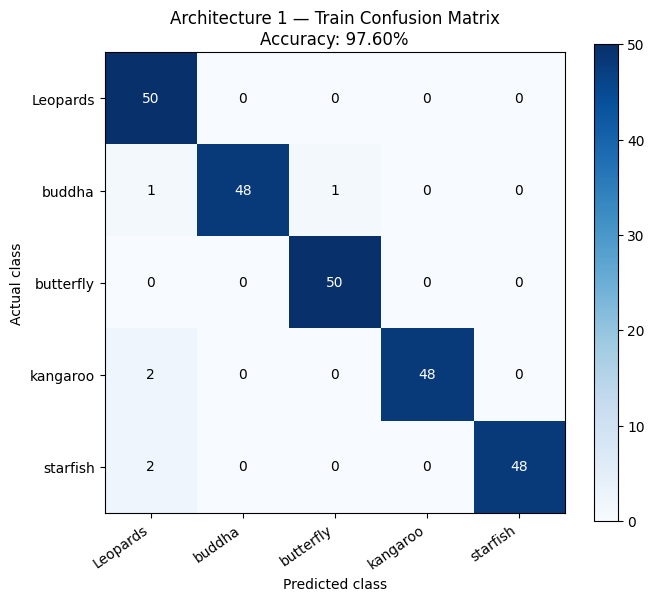

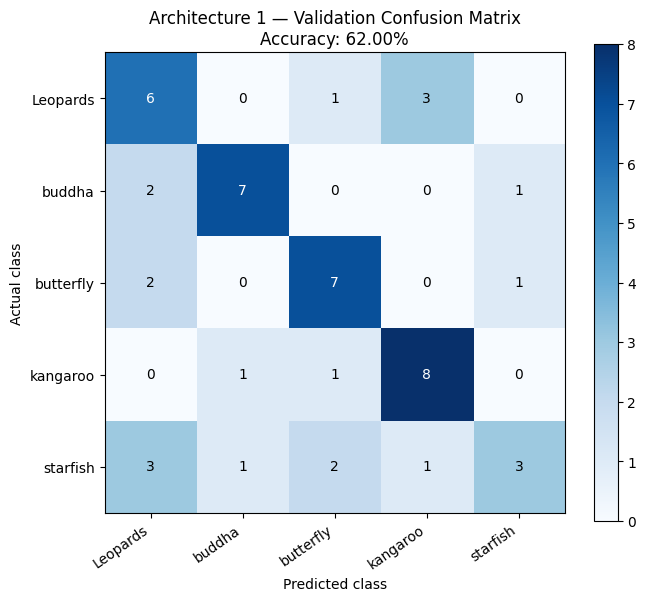

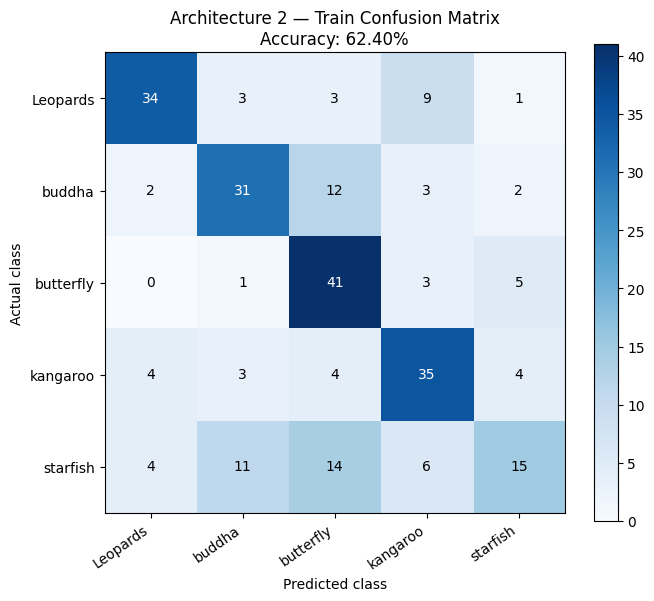

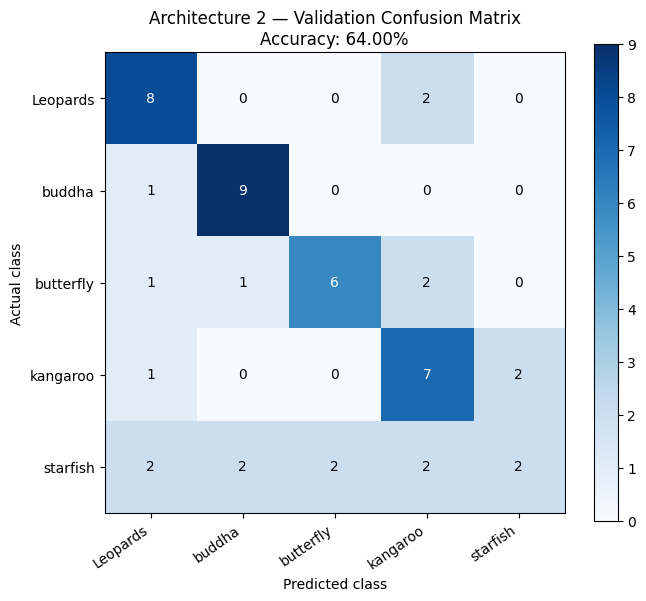

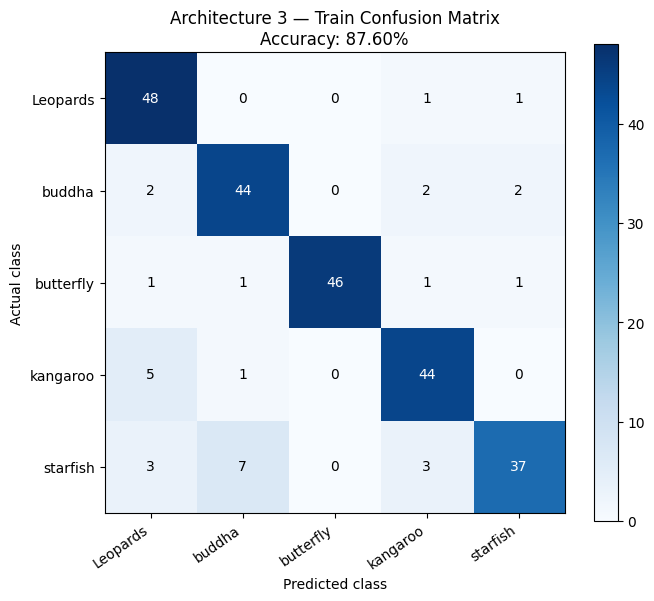

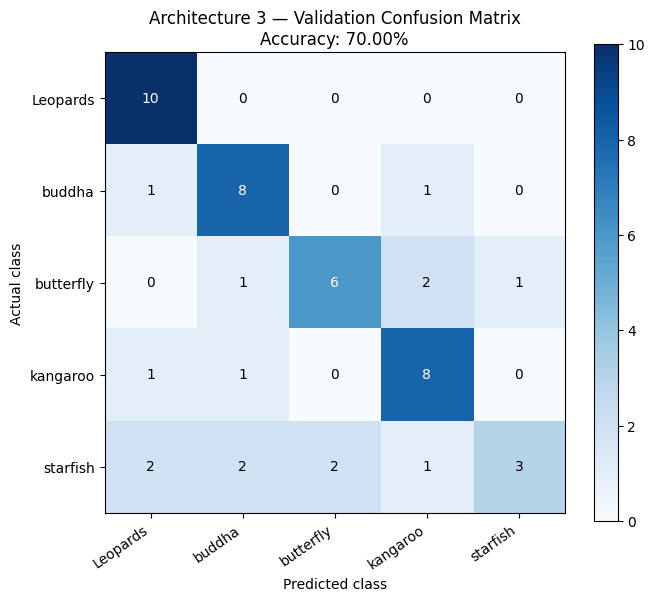

,Architecture,Split,Accuracy (%),Correct,Total
0,Architecture 1,Train,97.6,244,250
1,Architecture 1,Validation,62.0,31,50
2,Architecture 2,Train,62.4,156,250
3,Architecture 2,Validation,64.0,32,50
4,Architecture 3,Train,87.6,219,250
5,Architecture 3,Validation,70.0,35,50


Saved all confusion matrices and summary to: /kaggle/working/part_b_q1_results/q1a_confusion_matrices


In [28]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(
    DATA_ROOT / "train",
    transform=eval_transform
)
val_dataset = datasets.ImageFolder(
    DATA_ROOT / "val",
    transform=eval_transform
)

class_names = train_dataset.classes

assert val_dataset.classes == class_names, (
    "Training and validation class orders differ."
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=False, num_workers=2
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)


def load_checkpoint(model, checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path, map_location=device, weights_only=True
    )

    if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    state_dict = {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }

    model.load_state_dict(state_dict, strict=True)
    return model


def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = model(images)
            predictions = logits.argmax(dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    cm = confusion_matrix(
        y_true, y_pred, labels=list(range(len(class_names)))
    )
    accuracy = accuracy_score(y_true, y_pred)

    return accuracy, cm, y_true, y_pred


evaluation_results = {}
summary_rows = []

for architecture_name, model_class in model_classes.items():
    checkpoint_path = checkpoint_paths[architecture_name]

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint for {architecture_name}: "
            f"{checkpoint_path}\n"
            "Update checkpoint_paths using the file locations printed above."
        )

    model = model_class(num_classes=len(class_names)).to(device)
    model = load_checkpoint(model, checkpoint_path)

    for split_name, loader in [
        ("Train", train_loader),
        ("Validation", val_loader),
    ]:
        accuracy, cm, y_true, y_pred = evaluate_model(model, loader)

        evaluation_results[(architecture_name, split_name)] = {
            "accuracy": accuracy,
            "cm": cm,
            "y_true": y_true,
            "y_pred": y_pred,
        }

        summary_rows.append({
            "Architecture": architecture_name,
            "Split": split_name,
            "Accuracy (%)": round(accuracy * 100, 2),
            "Correct": int((y_true == y_pred).sum()),
            "Total": len(y_true),
        })

        # Save each confusion matrix as a CSV.
        cm_df = pd.DataFrame(
            cm, index=class_names, columns=class_names
        )
        cm_df.to_csv(
            OUTPUT_DIR /
            f"{architecture_name.lower().replace(' ', '_')}_"
            f"{split_name.lower()}_confusion_matrix.csv"
        )

        # Plot and save each confusion matrix.
        fig, ax = plt.subplots(figsize=(7, 6))
        im = ax.imshow(cm, cmap="Blues")
        fig.colorbar(im, ax=ax)

        ax.set_xticks(range(len(class_names)))
        ax.set_yticks(range(len(class_names)))
        ax.set_xticklabels(class_names, rotation=35, ha="right")
        ax.set_yticklabels(class_names)
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")
        ax.set_title(
            f"{architecture_name} — {split_name} Confusion Matrix\n"
            f"Accuracy: {accuracy * 100:.2f}%"
        )

        threshold = cm.max() / 2 if cm.max() > 0 else 0
        for i in range(len(class_names)):
            for j in range(len(class_names)):
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center",
                    color="white" if cm[i, j] > threshold else "black"
                )

        fig.tight_layout()
        fig.savefig(
            OUTPUT_DIR /
            f"{architecture_name.lower().replace(' ', '_')}_"
            f"{split_name.lower()}_confusion_matrix.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

summary_df.to_csv(
    OUTPUT_DIR / "q1a_train_validation_accuracy_summary.csv",
    index=False
)

print("Saved all confusion matrices and summary to:", OUTPUT_DIR)

In [29]:
import shutil

# Syntax: shutil.make_archive('output_filename', 'format', 'source_directory')
shutil.make_archive('q1a_confusion_matrices', 'zip', '/kaggle/working/part_b_q1_results/q1a_confusion_matrices')


'/kaggle/working/q1a_confusion_matrices.zip'

# **Q1 b**

In [23]:
from pathlib import Path
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ---------------------------------------------------------
# 1. Paths and configuration
# ---------------------------------------------------------
DATA_ROOT = Path(
    "/kaggle/input/datasets/aditya000001/"
    "group-16-caltech-101/Group_16" #
)

# CHANGE THIS to the exact path of your saved Architecture 3 model.
CHECKPOINT_PATH = Path(
    "/kaggle/input/models/aditya000001/model-q1b/pytorch/default/1/architecture_3_dropout.pt"
)

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results/q1b_test_evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use the same deterministic preprocessing as your validation dataset.
# If your validation pipeline uses normalization, reproduce it here.
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Lambda(lambda image: image.convert("RGB")),
    transforms.ToTensor()
])

test_dataset = datasets.ImageFolder(
    DATA_ROOT / "test",
    transform=eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

class_names = test_dataset.classes
num_classes = len(class_names)

print("Device:", device)
print("Classes:", class_names)
print("Test images:", len(test_dataset))
print("Images per class:", {
    name: sum(1 for _, label in test_dataset.samples
              if label == idx)
    for idx, name in enumerate(class_names)
})

assert num_classes == 5, f"Expected 5 classes, got {num_classes}"
assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}\n"
    "Update CHECKPOINT_PATH to your saved architecture_3_dropout file."
)

# ---------------------------------------------------------
# 2. Define the exact Architecture 3 with dropout
# ---------------------------------------------------------
class CNNArchitecture3(nn.Module):
    """Four convolutional layers; no pool after Conv3."""

    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=11, stride=4, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(8, 16, kernel_size=5, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 2 * 2, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = CNNArchitecture3(num_classes=num_classes).to(device)

# Support checkpoints saved as either a plain state_dict
# or a dictionary containing a state_dict.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

# Handle checkpoints saved from DataParallel, if applicable.
state_dict = {
    key.removeprefix("module."): value
    for key, value in state_dict.items()
}

model.load_state_dict(state_dict, strict=True)
model.eval()

print("Architecture 3 checkpoint loaded successfully!")
print("Dropout probability:", model.classifier[3].p)

Device: cuda
Classes: ['Leopards', 'buddha', 'butterfly', 'kangaroo', 'starfish']
Test images: 100
Images per class: {'Leopards': 20, 'buddha': 20, 'butterfly': 20, 'kangaroo': 20, 'starfish': 20}
Architecture 3 checkpoint loaded successfully!
Dropout probability: 0.5


In [24]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.asarray(all_labels)
all_predictions = np.asarray(all_predictions)
all_probabilities = np.asarray(all_probabilities)

test_accuracy = accuracy_score(all_labels, all_predictions)
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

print(f"\nArchitecture 3 + Dropout — Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Correct predictions: {(all_labels == all_predictions).sum()}/{len(all_labels)}")

print("\nConfusion Matrix")
print("Rows = actual class; columns = predicted class")
print(pd.DataFrame(cm, index=class_names, columns=class_names))

print("\nClassification Report")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
))


Architecture 3 + Dropout — Test Accuracy: 68.00%
Correct predictions: 68/100

Confusion Matrix
Rows = actual class; columns = predicted class
           Leopards  buddha  butterfly  kangaroo  starfish
Leopards         16       1          0         3         0
buddha            3      14          0         1         2
butterfly         0       3         16         0         1
kangaroo          6       3          0        10         1
starfish          0       6          2         0        12

Classification Report
              precision    recall  f1-score   support

    Leopards     0.6400    0.8000    0.7111        20
      buddha     0.5185    0.7000    0.5957        20
   butterfly     0.8889    0.8000    0.8421        20
    kangaroo     0.7143    0.5000    0.5882        20
    starfish     0.7500    0.6000    0.6667        20

    accuracy                         0.6800       100
   macro avg     0.7023    0.6800    0.6808       100
weighted avg     0.7023    0.6800    0.6808   

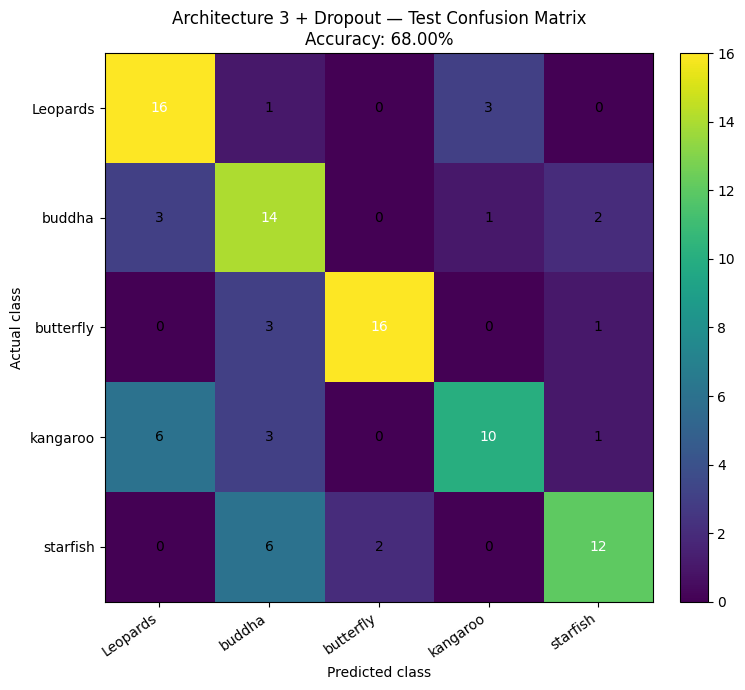

Saved confusion matrix: /kaggle/working/part_b_q1_results/q1b_test_evaluation/architecture_3_dropout_test_confusion_matrix.png
Saved evaluation files to: /kaggle/working/part_b_q1_results/q1b_test_evaluation


In [25]:
fig, ax = plt.subplots(figsize=(8, 7))

image = ax.imshow(cm, interpolation="nearest")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

ax.set(
    xticks=np.arange(num_classes),
    yticks=np.arange(num_classes),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="Actual class",
    title=f"Architecture 3 + Dropout — Test Confusion Matrix\n"
          f"Accuracy: {test_accuracy * 100:.2f}%"
)

plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

threshold = cm.max() / 2 if cm.max() > 0 else 0

for i in range(num_classes):
    for j in range(num_classes):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

fig.tight_layout()

cm_path = OUTPUT_DIR / "architecture_3_dropout_test_confusion_matrix.png"
fig.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved confusion matrix:", cm_path)

# Save the numeric confusion matrix too.
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    OUTPUT_DIR / "architecture_3_dropout_test_confusion_matrix.csv"
)

# Save individual test predictions.
test_results = pd.DataFrame({
    "image_path": [path for path, _ in test_dataset.samples],
    "actual_class": [class_names[i] for i in all_labels],
    "predicted_class": [class_names[i] for i in all_predictions],
    "correct": all_labels == all_predictions,
})

for i, class_name in enumerate(class_names):
    test_results[f"probability_{class_name}"] = all_probabilities[:, i]

test_results.to_csv(
    OUTPUT_DIR / "architecture_3_dropout_test_predictions.csv",
    index=False
)

print("Saved evaluation files to:", OUTPUT_DIR)

In [26]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    zero_division=0
)

summary = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Test samples": support.astype(int),
})

display(summary.round(4))

print(f"Selected architecture: Architecture 3 + Dropout (p=0.5)")
print(f"Validation accuracy used for selection: use your recorded value")
print(f"Final test accuracy: {test_accuracy * 100:.2f}%")

,Class,Precision,Recall,F1-score,Test samples
0,Leopards,0.6400,0.8,0.7111,20
1,buddha,0.5185,0.7,0.5957,20
2,butterfly,0.8889,0.8,0.8421,20
3,kangaroo,0.7143,0.5,0.5882,20
4,starfish,0.7500,0.6,0.6667,20


Selected architecture: Architecture 3 + Dropout (p=0.5)
Validation accuracy used for selection: use your recorded value
Final test accuracy: 68.00%


Q1. c

In [57]:

from pathlib import Path
import json
import torch
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save every trained architecture checkpoint.
for name, model in trained_models.items():
    filename = f"{name.lower().replace('-', '_')}_dropout.pt"
    torch.save(model.state_dict(), OUTPUT_DIR / filename)

# Save the architecture comparison table.
comparison_df.to_csv(
    OUTPUT_DIR / "architecture_comparison_dropout.csv",
    index=False
)

# Select the winner by validation accuracy.
best_architecture_name = comparison_df.loc[
    comparison_df["Validation accuracy (%)"].idxmax(),
    "Architecture"
]
best_model = trained_models[best_architecture_name].to(device)
best_model.eval()

print("Selected architecture:", best_architecture_name)
print("Saved model checkpoints and comparison CSV.")
print("Output directory:", OUTPUT_DIR)


Selected architecture: Architecture-3
Saved model checkpoints and comparison CSV.
Output directory: /kaggle/working/part_b_q1_results


In [58]:

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

# Use one training image and preserve its original class label.
image_tensor, label_idx = train_dataset[0]
input_batch = image_tensor.unsqueeze(0).to(device)

best_model.eval()

# Architecture-3 has Conv/ReLU pairs at these indices.
conv_relu_indices = [1, 4, 7, 9]
feature_maps = {}
hooks = []

def make_hook(layer_name):
    def hook(module, inputs, output):
        feature_maps[layer_name] = output.detach().cpu()[0]
    return hook

for layer_number, layer_index in enumerate(conv_relu_indices, start=1):
    layer = best_model.features[layer_index]
    hooks.append(
        layer.register_forward_hook(make_hook(f"Conv{layer_number}"))
    )

with torch.no_grad():
    logits = best_model(input_batch)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

for hook in hooks:
    hook.remove()

predicted_idx = int(np.argmax(probabilities))

print("True class:", class_names[label_idx])
print("Predicted class:", class_names[predicted_idx])
print("Class probabilities:")
for name, probability in zip(class_names, probabilities):
    print(f"  {name}: {probability:.4f}")

for layer_name, activations in feature_maps.items():
    print(layer_name, tuple(activations.shape))


True class: Leopards
Predicted class: Leopards
Class probabilities:
  Leopards: 0.5685
  buddha: 0.0871
  butterfly: 0.0170
  kangaroo: 0.2149
  starfish: 0.1124
Conv1 (8, 54, 54)
Conv2 (16, 22, 22)
Conv3 (32, 8, 8)
Conv4 (64, 6, 6)


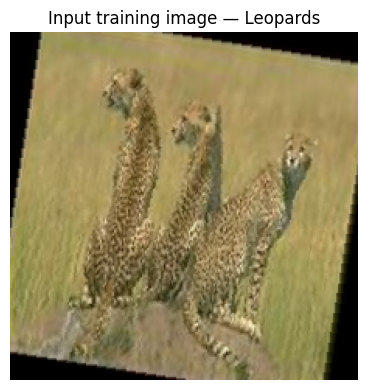

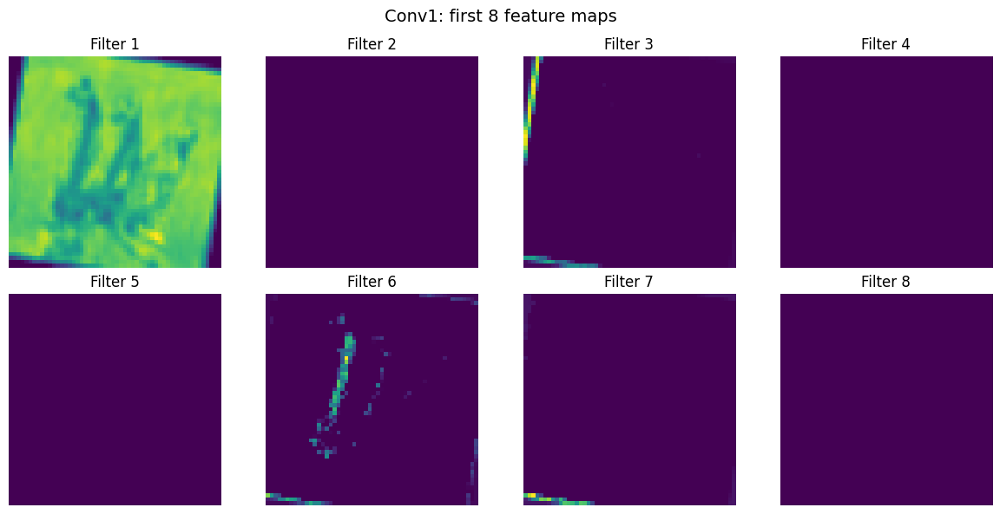

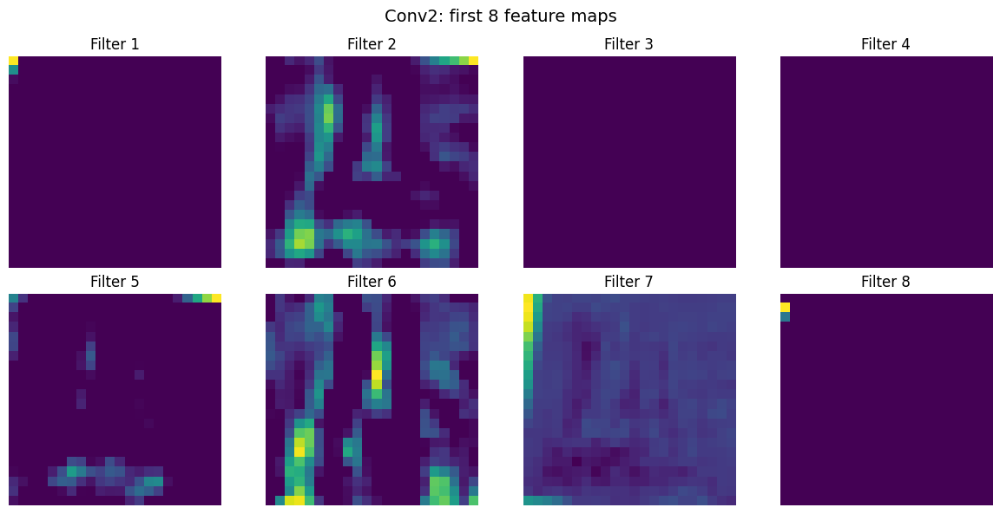

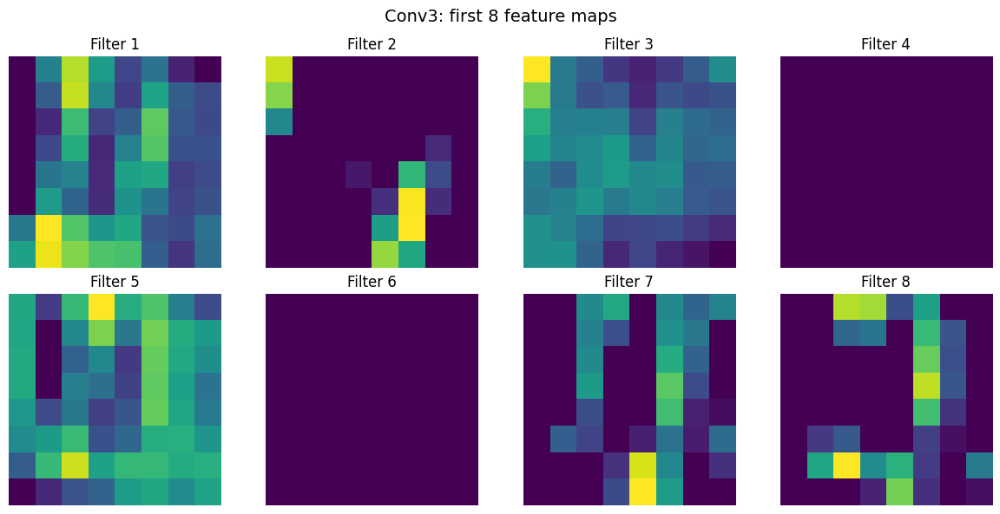

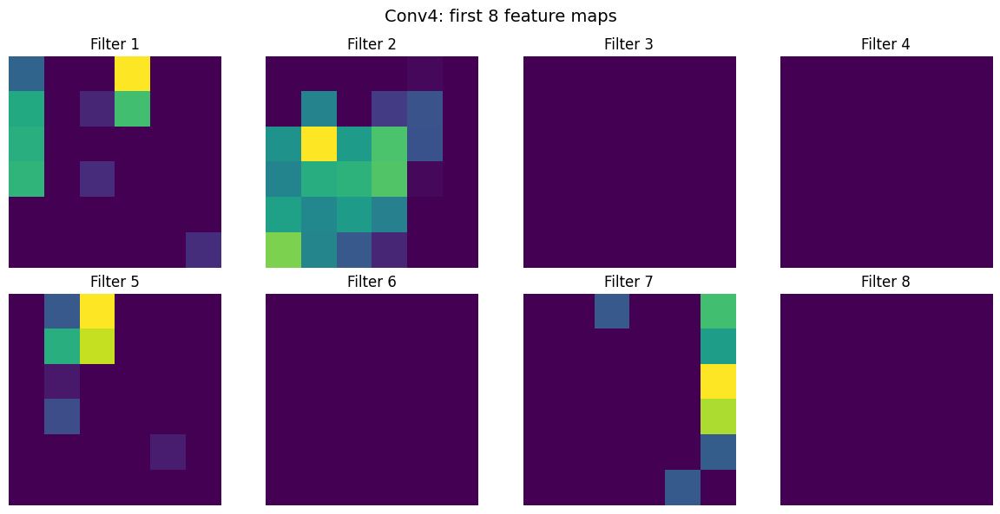

Q1(c) feature-map figures saved.


In [59]:

# Display the input image.
plt.figure(figsize=(4, 4))
plt.imshow(image_tensor.permute(1, 2, 0).numpy())
plt.title(f"Input training image — {class_names[label_idx]}")
plt.axis("off")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "q1c_input_training_image.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

for layer_name, activations in feature_maps.items():
    num_maps = min(8, activations.shape[0])

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    fig.suptitle(
        f"{layer_name}: first {num_maps} feature maps",
        fontsize=14
    )

    for channel in range(8):
        ax = axes.flat[channel]
        if channel < num_maps:
            ax.imshow(activations[channel].numpy(), cmap="viridis")
            ax.set_title(f"Filter {channel + 1}")
        ax.axis("off")

    plt.tight_layout()
    filename = f"q1c_{layer_name.lower()}_feature_maps.png"
    fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Q1(c) feature-map figures saved.")


In [20]:

# Choose the first training example for each class.
# ImageFolder stores targets in the same order as dataset.samples.
representative_indices = {}

for index, (_, target) in enumerate(train_dataset.samples):
    if target not in representative_indices:
        representative_indices[target] = index

    if len(representative_indices) == len(class_names):
        break

print("Representative training images:")
for class_idx, index in sorted(representative_indices.items()):
    print(class_names[class_idx], "-> dataset index", index)


Representative training images:
Leopards -> dataset index 0
buddha -> dataset index 50
butterfly -> dataset index 100
kangaroo -> dataset index 150
starfish -> dataset index 200


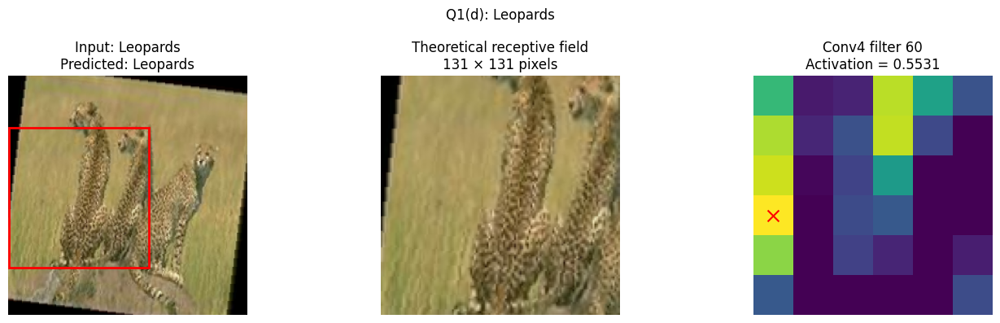

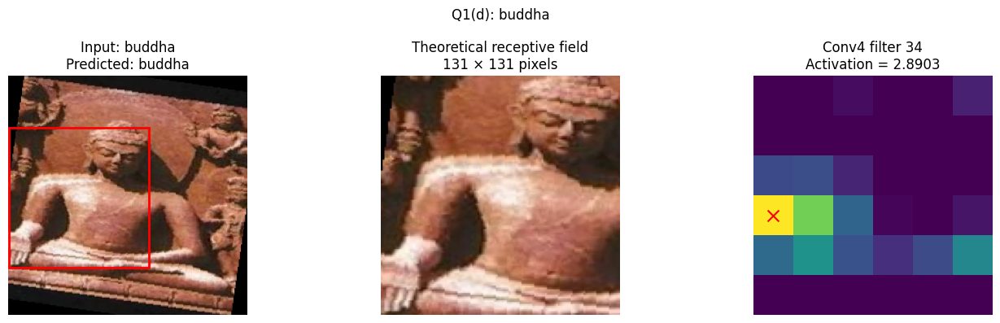

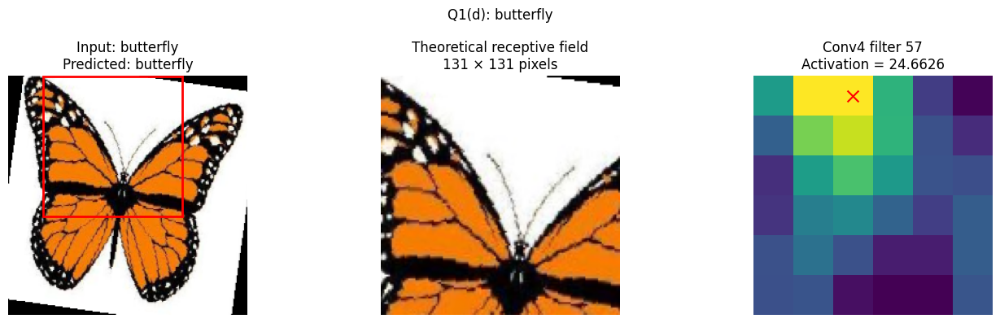

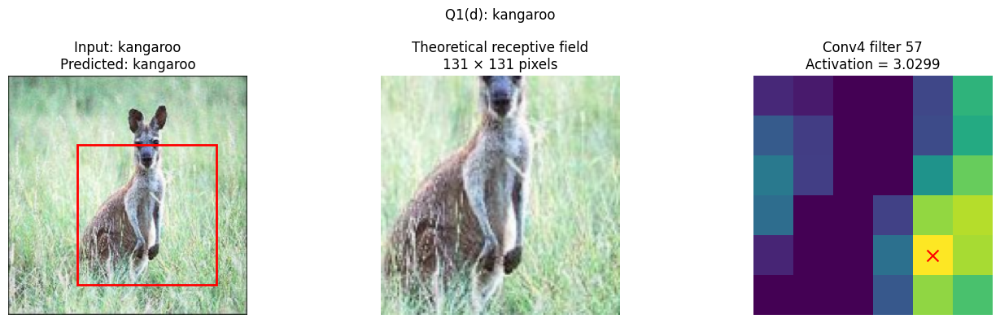

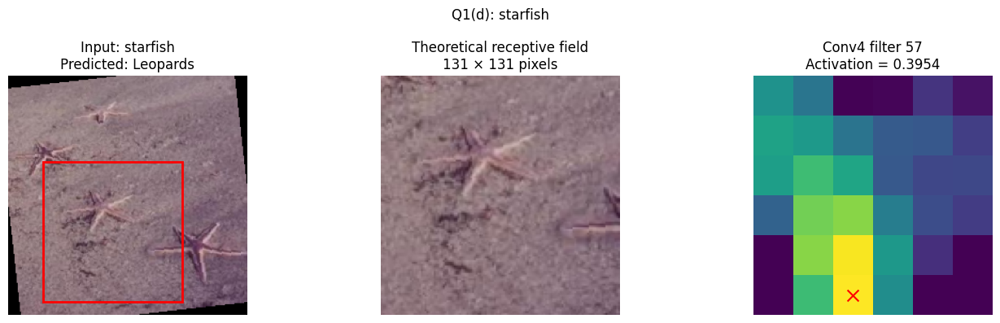

Q1(d) results:


,true_class,predicted_class,max_activation,filter,feature_row,feature_col,rf_x0,rf_y0,rf_x1,rf_y1
0,Leopards,Leopards,0.553124,60,3,0,0,48,131,179
1,buddha,buddha,2.890338,34,3,0,0,48,131,179
2,butterfly,butterfly,24.662565,57,0,2,32,0,163,131
3,kangaroo,kangaroo,3.029910,57,4,4,64,64,195,195
4,starfish,Leopards,0.395422,57,5,2,32,80,163,211


In [66]:

from matplotlib.patches import Rectangle

# For Conv4, the receptive field is 131 x 131 pixels.
RF_SIZE = 131
RF_JUMP = 16

conv4_layer = best_model.features[9]
all_class_results = []

for class_idx, dataset_index in sorted(representative_indices.items()):
    image_tensor, true_label = train_dataset[dataset_index]
    batch = image_tensor.unsqueeze(0).to(device)

    captured = {}

    def conv4_hook(module, inputs, output):
        captured["conv4"] = output.detach().cpu()[0]

    handle = conv4_layer.register_forward_hook(conv4_hook)

    best_model.eval()
    with torch.no_grad():
        logits = best_model(batch)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    handle.remove()

    activation = captured["conv4"]  # (64, 6, 6)

    # Find the single strongest activation over channel and spatial positions.
        # activation shape: (64, 6, 6)
    assert activation.shape == (64, 6, 6), activation.shape
    
    # Get the channel, row, and column directly.
    channel, row, col = torch.unravel_index(
        torch.argmax(activation),
        activation.shape
    )
    
    channel = int(channel.item())
    row = int(row.item())
    col = int(col.item())
    
    max_activation = activation[channel, row, col].item()

    # The theoretical RF starts at (col * jump, row * jump).
    x0 = col * RF_JUMP
    y0 = row * RF_JUMP
    x1 = min(x0 + RF_SIZE, 224)
    y1 = min(y0 + RF_SIZE, 224)

    predicted_idx = int(np.argmax(probs))

    all_class_results.append({
        "true_class": class_names[true_label],
        "predicted_class": class_names[predicted_idx],
        "max_activation": max_activation,
        "filter": channel + 1,
        "feature_row": row,
        "feature_col": col,
        "rf_x0": x0,
        "rf_y0": y0,
        "rf_x1": x1,
        "rf_y1": y1,
    })

    image_np = image_tensor.permute(1, 2, 0).numpy()
    patch = image_np[y0:y1, x0:x1, :]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    axes[0].imshow(image_np)
    axes[0].set_title(
        f"Input: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_idx]}"
    )
    axes[0].add_patch(Rectangle(
        (x0, y0), x1 - x0, y1 - y0,
        fill=False, edgecolor="red", linewidth=2
    ))
    axes[0].axis("off")

    axes[1].imshow(patch)
    axes[1].set_title(
        f"Theoretical receptive field\n"
        f"{x1 - x0} × {y1 - y0} pixels"
    )
    axes[1].axis("off")

    axes[2].imshow(activation[channel].numpy(), cmap="viridis")
    axes[2].scatter([col], [row], c="red", marker="x", s=100)
    axes[2].set_title(
        f"Conv4 filter {channel + 1}\n"
        f"Activation = {max_activation:.4f}"
    )
    axes[2].axis("off")

    fig.suptitle(f"Q1(d): {class_names[true_label]}")
    plt.tight_layout()

    filename = (
        f"q1d_{class_names[true_label].lower()}_receptive_field.png"
    )
    fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Save a table of the selected neurons and receptive fields.
rf_df = pd.DataFrame(all_class_results)
rf_df.to_csv(OUTPUT_DIR / "q1d_receptive_field_results.csv", index=False)

print("Q1(d) results:")
display(rf_df)


# **Question 2**

In [13]:
from torchvision import datasets, models
from torch.utils.data import DataLoader

weights = models.VGG19_Weights.DEFAULT
vgg_transform = weights.transforms()

train_dataset_vgg = datasets.ImageFolder(
    str(TRAIN_DIR), transform=vgg_transform
)
val_dataset_vgg = datasets.ImageFolder(
    str(VAL_DIR), transform=vgg_transform
)
test_dataset_vgg = datasets.ImageFolder(
    str(TEST_DIR), transform=vgg_transform
)

# Preserve your existing batch size and worker settings if different.
train_loader = DataLoader(
    train_dataset_vgg, batch_size=16, shuffle=True
)
val_loader = DataLoader(
    val_dataset_vgg, batch_size=16, shuffle=False
)
test_loader = DataLoader(
    test_dataset_vgg, batch_size=16, shuffle=False
)

assert train_dataset_vgg.class_to_idx == val_dataset_vgg.class_to_idx
assert train_dataset_vgg.class_to_idx == test_dataset_vgg.class_to_idx

print("Class mapping:", train_dataset_vgg.class_to_idx)
print("VGG19 preprocessing:", vgg_transform)

Class mapping: {'Leopards': 0, 'buddha': 1, 'butterfly': 2, 'kangaroo': 3, 'starfish': 4}
VGG19 preprocessing: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [15]:
from torchvision import models

#import vgg19

from torchvision import models
import torch.nn as nn

model = models.vgg19(
    weights=models.VGG19_Weights.DEFAULT
)

# Freeze all pretrained parameters.
for param in model.parameters():
    param.requires_grad = False

# Replace the final classifier layer with 5 output classes.
in_features = model.classifier[6].in_features
model.classifier[6] = nn.Linear(in_features, 5)

model = model.to(device)

# The new final layer is trainable.
for param in model.classifier[6].parameters():
    param.requires_grad = True

# Verify that only the final layer is trainable.
trainable = [
    name for name, param in model.named_parameters()
    if param.requires_grad
]
print("Trainable parameters:", trainable)

assert trainable == [
    "classifier.6.weight",
    "classifier.6.bias"
]




import copy
import time
import json

EPOCHS = 100
LEARNING_RATE = 1e-3
PATIENCE = 10

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.cpu().numpy().tolist())
        all_pred.extend(predictions.cpu().numpy().tolist())

    mean_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_true, all_pred)

    return mean_loss, accuracy, all_true, all_pred


def train_architecture(name, model):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }

    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc, _, _ = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc, _, _ = run_epoch(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if epoch %5 ==0:
            print(
                f"{name} | Epoch {epoch:02d}/{EPOCHS} | "
                f"Train loss={train_loss:.4f}, "
                f"Train acc={train_acc:.4f} | "
                f"Val loss={val_loss:.4f}, "
                f"Val acc={val_acc:.4f}"
            )

        improved = (
            val_acc > best_val_accuracy
            or (
                val_acc == best_val_accuracy
                and val_loss < best_val_loss
            )
        )
        
        if improved:
            best_val_accuracy = val_acc
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    model.load_state_dict(best_state)

    checkpoint_path = OUTPUT_DIR / f"{name.lower().replace('-', '_')}_VGG_19_default.pt"
    torch.save(model.state_dict(), checkpoint_path)

    elapsed = (time.time() - start) / 60

    print(
        f"\n{name}: best epoch={best_epoch}, "
        f"best validation loss={best_val_loss:.4f}, "
        f"time={elapsed:.2f} minutes\n"
    )

    return model, history, best_epoch


trained_models = {}
histories = {}
best_epochs = {}

model, history, best_epoch = train_architecture(
    "VGG19", model
)
trained_models["VGG19"] = model
histories["VGG19"] = history
best_epochs["VGG19"] = best_epoch

print("All architecture training runs finished.")


Trainable parameters: ['classifier.6.weight', 'classifier.6.bias']
VGG19 | Epoch 05/100 | Train loss=0.0087, Train acc=1.0000 | Val loss=0.0076, Val acc=1.0000
VGG19 | Epoch 10/100 | Train loss=0.0051, Train acc=1.0000 | Val loss=0.0056, Val acc=1.0000
VGG19 | Epoch 15/100 | Train loss=0.0023, Train acc=1.0000 | Val loss=0.0049, Val acc=1.0000
VGG19 | Epoch 20/100 | Train loss=0.0020, Train acc=1.0000 | Val loss=0.0038, Val acc=1.0000
VGG19 | Epoch 25/100 | Train loss=0.0014, Train acc=1.0000 | Val loss=0.0035, Val acc=1.0000
VGG19 | Epoch 30/100 | Train loss=0.0010, Train acc=1.0000 | Val loss=0.0031, Val acc=1.0000
VGG19 | Epoch 35/100 | Train loss=0.0014, Train acc=1.0000 | Val loss=0.0028, Val acc=1.0000
VGG19 | Epoch 40/100 | Train loss=0.0006, Train acc=1.0000 | Val loss=0.0026, Val acc=1.0000
VGG19 | Epoch 45/100 | Train loss=0.0007, Train acc=1.0000 | Val loss=0.0022, Val acc=1.0000
VGG19 | Epoch 50/100 | Train loss=0.0006, Train acc=1.0000 | Val loss=0.0022, Val acc=1.0000
VGG

,Architecture,Best epoch,Training accuracy (%),Validation accuracy (%),Training loss,Validation loss
0,VGG19,79,100.0,100.0,0.0002,0.0014


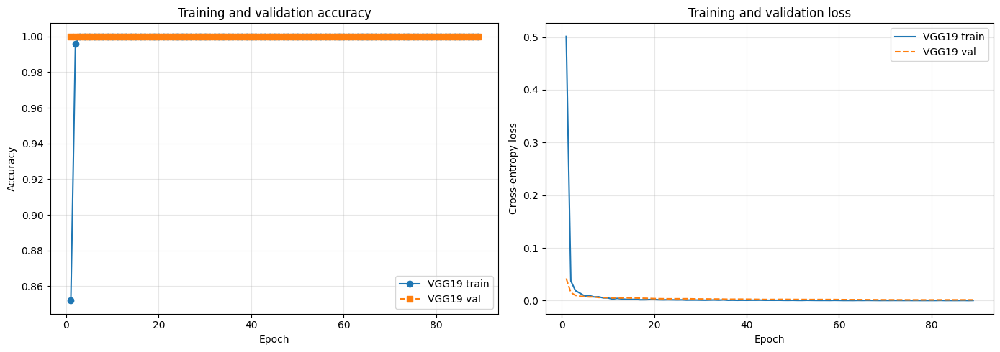

In [16]:

comparison_rows = []

for name, history in histories.items():
    best_index = best_epochs[name] - 1

    comparison_rows.append({
        "Architecture": name,
        "Best epoch": best_epochs[name],
        "Training accuracy (%)":
            100 * history["train_accuracy"][best_index],
        "Validation accuracy (%)":
            100 * history["val_accuracy"][best_index],
        "Training loss": history["train_loss"][best_index],
        "Validation loss": history["val_loss"][best_index],
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

comparison_df.to_csv(
    OUTPUT_DIR / "architecture_comparison_VGG_19_default.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():
    epochs = range(1, len(history["train_accuracy"]) + 1)

    axes[0].plot(
        epochs, history["train_accuracy"],
        marker="o", label=name + " train"
    )
    axes[0].plot(
        epochs, history["val_accuracy"],
        marker="s", linestyle="--", label=name + " val"
    )

    axes[1].plot(
        epochs, history["train_loss"],
        label=name + " train"
    )
    axes[1].plot(
        epochs, history["val_loss"],
        linestyle="--", label=name + " val"
    )

axes[0].set_title("Training and validation accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and validation loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "architecture_learning_curves_VGG_19_default.png", dpi=200)
plt.show()



TRAIN accuracy: 1.0000
TRAIN loss: 0.000124
[[50  0  0  0  0]
 [ 0 50  0  0  0]
 [ 0  0 50  0  0]
 [ 0  0  0 50  0]
 [ 0  0  0  0 50]]


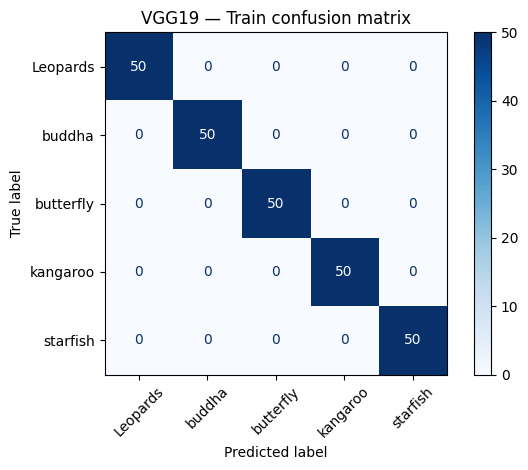


VALIDATION accuracy: 1.0000
VALIDATION loss: 0.001434
[[10  0  0  0  0]
 [ 0 10  0  0  0]
 [ 0  0 10  0  0]
 [ 0  0  0 10  0]
 [ 0  0  0  0 10]]


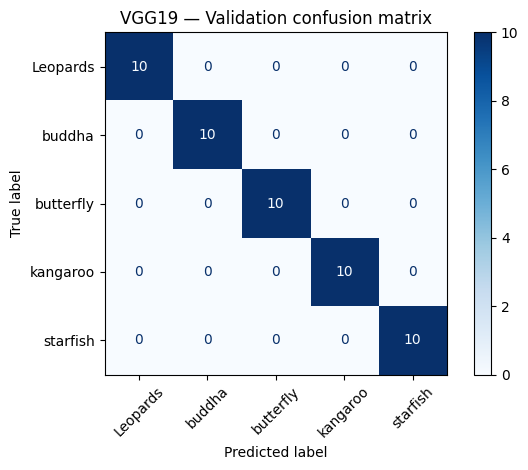


TEST accuracy: 0.9900
TEST loss: 0.014429
[[20  0  0  0  0]
 [ 0 20  0  0  0]
 [ 0  0 19  0  1]
 [ 0  0  0 20  0]
 [ 0  0  0  0 20]]


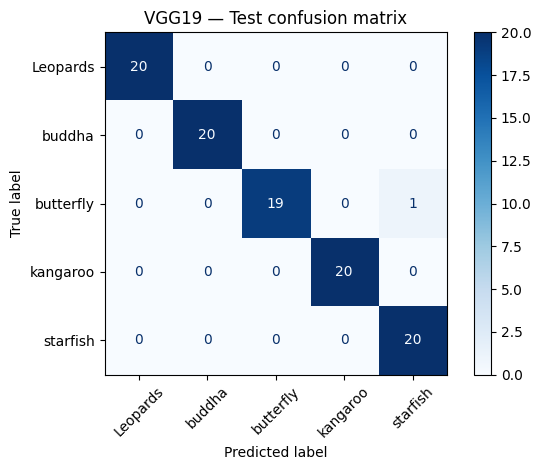


Saved final metrics and confusion matrices to: /kaggle/working/part_b_q1_results


In [18]:

# Final evaluation for VGG19 — default pretrained transformation
# Requires: model, train_loader, val_loader, test_loader, device,
#           class_names, criterion, OUTPUT_DIR

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import json
import torch

criterion = nn.CrossEntropyLoss()
model.eval()
final_metrics = {}

for split_name, loader in [
    ("train", train_loader),
    ("validation", val_loader),
    ("test", test_loader),
]:
    y_true, y_pred = [], []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)

            y_true.extend(labels.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    accuracy = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))

    final_metrics[split_name] = {
        "accuracy": float(accuracy),
        "loss": float(total_loss / len(loader.dataset)),
        "confusion_matrix": cm.tolist(),
        "classification_report": classification_report(
            y_true, y_pred,
            labels=list(range(len(class_names))),
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
    }

    print(f"\n{split_name.upper()} accuracy: {accuracy:.4f}")
    print(f"{split_name.upper()} loss: {final_metrics[split_name]['loss']:.6f}")
    print(cm)

    disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
    disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
    plt.title(f"VGG19 — {split_name.title()} confusion matrix")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"vgg19_default_{split_name}_confusion_matrix.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    plt.close()

with open(OUTPUT_DIR / "vgg19_default_final_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

print("\nSaved final metrics and confusion matrices to:", OUTPUT_DIR)


In [21]:

# Recover the five representative images used for Q1(d)
# Uses the existing train_dataset and representative_indices.

from pathlib import Path
import pandas as pd

recovered_images = []

for class_idx, dataset_index in sorted(representative_indices.items()):
    image_path, target = train_dataset.samples[dataset_index]

    recovered_images.append({
        "class": class_names[class_idx],
        "dataset_index": dataset_index,
        "filename": Path(image_path).name,
        "full_path": image_path,
    })

recovered_df = pd.DataFrame(recovered_images)
display(recovered_df)

recovered_df.to_csv(
    OUTPUT_DIR / "q1d_recovered_training_image_names.csv",
    index=False
)

print("Saved filenames to:", OUTPUT_DIR / "q1d_recovered_training_image_names.csv")


,class,dataset_index,filename,full_path
0,Leopards,0,image_0004.jpg,/kaggle/input/datasets/aditya000001/group-16-c...
1,buddha,50,image_0001.jpg,/kaggle/input/datasets/aditya000001/group-16-c...
2,butterfly,100,image_0001.jpg,/kaggle/input/datasets/aditya000001/group-16-c...
3,kangaroo,150,image_0002.jpg,/kaggle/input/datasets/aditya000001/group-16-c...
4,starfish,200,image_0002.jpg,/kaggle/input/datasets/aditya000001/group-16-c...


Saved filenames to: /kaggle/working/part_b_q1_results/q1d_recovered_training_image_names.csv


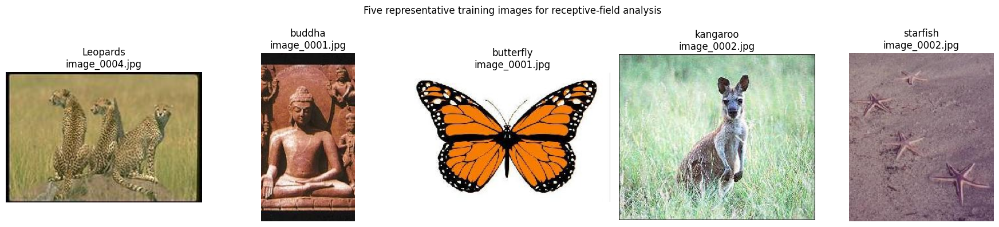

In [22]:

# Load the same five image files using VGG19's default preprocessing.
# Requires train_dataset_vgg and representative_indices from your notebook.

from PIL import Image
import matplotlib.pyplot as plt

weights = models.VGG19_Weights.DEFAULT
vgg_transform = weights.transforms()

fig, axes = plt.subplots(1, len(representative_indices), figsize=(18, 4))

for ax, (class_idx, dataset_index) in zip(
    axes, sorted(representative_indices.items())
):
    image_path, _ = train_dataset.samples[dataset_index]

    # Apply the exact pretrained VGG19 inference transformation.
    image = Image.open(image_path).convert("RGB")
    image_tensor = vgg_transform(image)

    # Display the original image for reference.
    ax.imshow(image)
    ax.set_title(f"{class_names[class_idx]}\n{Path(image_path).name}")
    ax.axis("off")

plt.suptitle("Five representative training images for receptive-field analysis")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "representative_images_for_vgg19_q2.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# **2B**

In [23]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models
from matplotlib.patches import Rectangle

# Paths
DATASET_ROOT = Path(
    "/kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16"
)
CHECKPOINT_PATH = Path(
    "/kaggle/working/part_b_q1_results/vgg19_VGG_19_default.pt"
)
OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results/vgg19_q2_receptive_fields")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT_PATH.exists(), f"Checkpoint not found: {CHECKPOINT_PATH}"

# VGG19 default preprocessing
weights = models.VGG19_Weights.DEFAULT
vgg_transform = weights.transforms()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Rebuild the same 5-class VGG19 architecture
model = models.vgg19(weights=None)
model.classifier[6] = nn.Linear(model.classifier[6].in_features, 5)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

class_names = ["Leopards", "buddha", "butterfly", "kangaroo", "starfish"]

representative_filenames = {
    "Leopards": "image_0004.jpg",
    "buddha": "image_0001.jpg",
    "butterfly": "image_0001.jpg",
    "kangaroo": "image_0002.jpg",
    "starfish": "image_0002.jpg",
}

print("Checkpoint loaded successfully.")
print("Output directory:", OUTPUT_DIR)


Device: cuda
Checkpoint loaded successfully.
Output directory: /kaggle/working/part_b_q1_results/vgg19_q2_receptive_fields


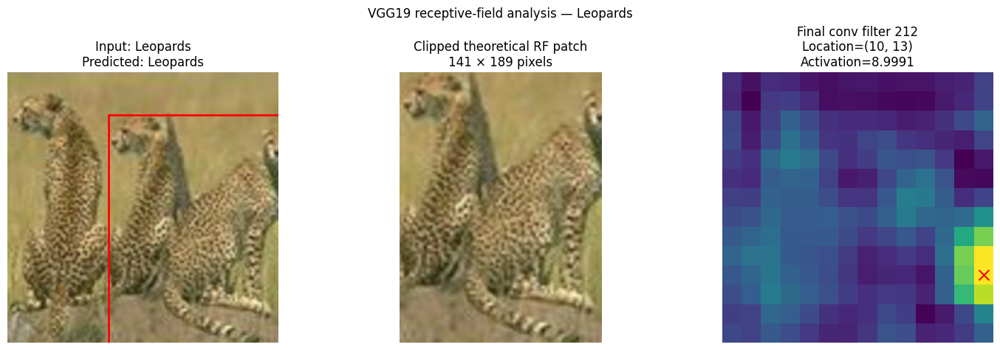

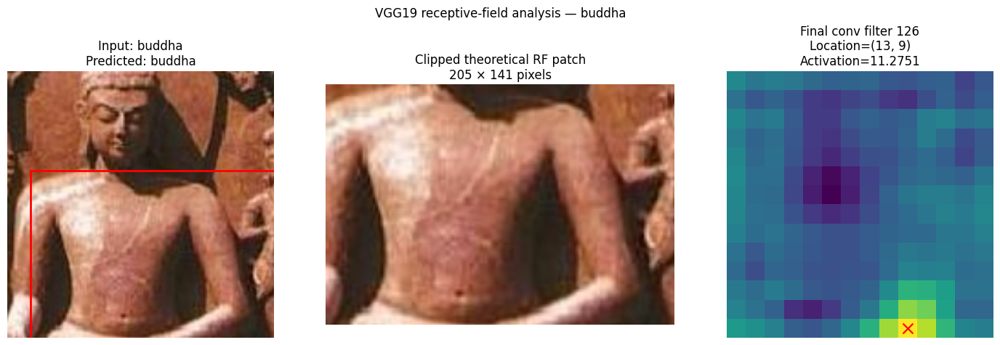

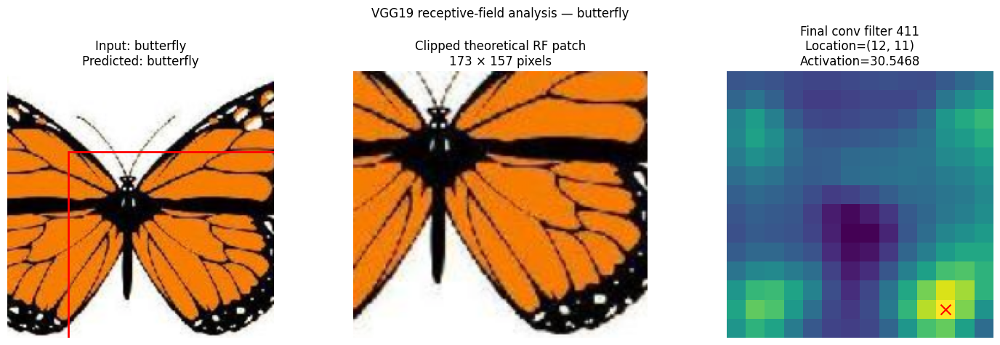

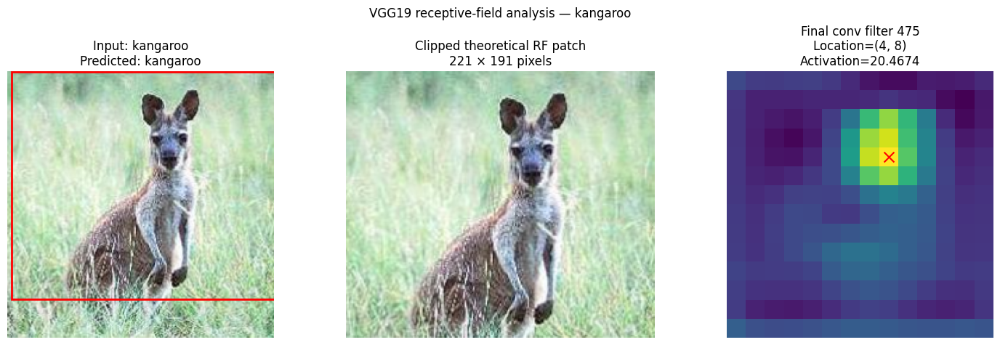

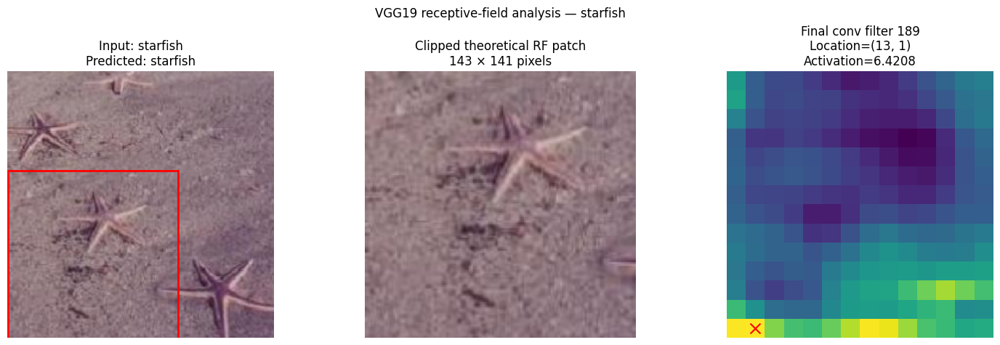

Receptive-field analysis complete.


,true_class,filename,predicted_class,correct_prediction,max_activation,filter_number_one_based,feature_row,feature_col,rf_x0,rf_y0,rf_x1,rf_y1
0,Leopards,image_0004.jpg,Leopards,True,8.999119,212,10,13,83,35,224,224
1,buddha,image_0001.jpg,buddha,True,11.275083,126,13,9,19,83,224,224
2,butterfly,image_0001.jpg,butterfly,True,30.546791,411,12,11,51,67,224,224
3,kangaroo,image_0002.jpg,kangaroo,True,20.467426,475,4,8,3,0,224,191
4,starfish,image_0002.jpg,starfish,True,6.420837,189,13,1,0,83,143,224


Saved to: /kaggle/working/part_b_q1_results/vgg19_q2_receptive_fields


In [26]:

# VGG19 final convolutional layer: features[34]
last_conv = model.features[34]
captured = {}

def capture_last_conv(module, inputs, output):
    captured["activation"] = output.detach().cpu()[0]

hook_handle = last_conv.register_forward_hook(capture_last_conv)

RF_SIZE = 252
RF_JUMP = 16
IMAGE_SIZE = 224

results = []

try:
    for class_name, filename in representative_filenames.items():
        image_path = DATASET_ROOT / "train" / class_name / filename
        if not image_path.exists():
            raise FileNotFoundError(f"Could not find image: {image_path}")

        original_image = Image.open(image_path).convert("RGB")
        image_tensor = vgg_transform(original_image)
        batch = image_tensor.unsqueeze(0).to(device)

        # Reconstruct the transformed image for visualization FIRST.
        mean = torch.tensor(weights.transforms().mean).view(3, 1, 1)
        std = torch.tensor(weights.transforms().std).view(3, 1, 1)
        display_tensor = image_tensor.cpu() * std + mean
        display_image = (
            display_tensor.permute(1, 2, 0).numpy().clip(0, 1)
        )

        captured.clear()
        with torch.no_grad():
            logits = model(batch)
            probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

        predicted_idx = int(np.argmax(probabilities))
        activation = captured["activation"]  # (512, 14, 14)

        # Find the strongest activation over all channels and positions.
        flat_index = int(torch.argmax(activation).item())
        channel, spatial_index = divmod(
            flat_index, activation.shape[1] * activation.shape[2]
        )
        row, col = divmod(spatial_index, activation.shape[2])
        max_activation = float(activation[channel, row, col])

        # Theoretical RF for the selected convolutional activation.
        center_x = col * RF_JUMP + 0.5
        center_y = row * RF_JUMP + 0.5

        raw_x0 = int(np.floor(center_x - (RF_SIZE - 1) / 2))
        raw_y0 = int(np.floor(center_y - (RF_SIZE - 1) / 2))
        raw_x1 = raw_x0 + RF_SIZE
        raw_y1 = raw_y0 + RF_SIZE

        x0 = max(0, raw_x0)
        y0 = max(0, raw_y0)
        x1 = min(IMAGE_SIZE, raw_x1)
        y1 = min(IMAGE_SIZE, raw_y1)

        patch = display_image[y0:y1, x0:x1, :]
        if patch.size == 0:
            raise ValueError(
                f"Empty patch for {class_name}: {(x0, y0, x1, y1)}"
            )

        results.append({
            "true_class": class_name,
            "filename": filename,
            "predicted_class": class_names[predicted_idx],
            "correct_prediction": class_names[predicted_idx] == class_name,
            "max_activation": max_activation,
            "filter_index_zero_based": channel,
            "filter_number_one_based": channel + 1,
            "feature_row": row,
            "feature_col": col,
            "rf_x0": x0,
            "rf_y0": y0,
            "rf_x1": x1,
            "rf_y1": y1,
            "rf_width_clipped": x1 - x0,
            "rf_height_clipped": y1 - y0,
            "predicted_probabilities": json.dumps({
                name: float(probabilities[i])
                for i, name in enumerate(class_names)
            }),
        })

        fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

        axes[0].imshow(display_image)
        axes[0].add_patch(Rectangle(
            (x0, y0), x1 - x0, y1 - y0,
            fill=False, edgecolor="red", linewidth=2
        ))
        axes[0].set_title(
            f"Input: {class_name}\n"
            f"Predicted: {class_names[predicted_idx]}"
        )
        axes[0].axis("off")

        axes[1].imshow(patch)
        axes[1].set_title(
            f"Clipped theoretical RF patch\n"
            f"{patch.shape[1]} × {patch.shape[0]} pixels"
        )
        axes[1].axis("off")

        axes[2].imshow(activation[channel].numpy(), cmap="viridis")
        axes[2].scatter([col], [row], c="red", marker="x", s=100)
        axes[2].set_title(
            f"Final conv filter {channel + 1}\n"
            f"Location=({row}, {col})\n"
            f"Activation={max_activation:.4f}"
        )
        axes[2].axis("off")

        fig.suptitle(f"VGG19 receptive-field analysis — {class_name}")
        plt.tight_layout()

        safe_class = class_name.lower().replace(" ", "_")
        fig.savefig(
            OUTPUT_DIR / f"q2_{safe_class}_receptive_field.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
        plt.close(fig)

finally:
    hook_handle.remove()

results_df = pd.DataFrame(results)
results_df.to_csv(
    OUTPUT_DIR / "vgg19_receptive_field_results.csv", index=False
)

with open(OUTPUT_DIR / "vgg19_receptive_field_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Receptive-field analysis complete.")
display(results_df[[
    "true_class", "filename", "predicted_class", "correct_prediction",
    "max_activation", "filter_number_one_based",
    "feature_row", "feature_col", "rf_x0", "rf_y0", "rf_x1", "rf_y1"
]])
print("Saved to:", OUTPUT_DIR)


In [4]:

from torchvision import models

CHECKPOINT_PATH = Path(
    "/kaggle/input/models/aditya000001/vgg-19/pytorch/default/1/vgg19_VGG_19_default.pt"
)

weights = models.VGG19_Weights.DEFAULT
vgg_transform = weights.transforms()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vgg_model = models.vgg19(weights=None)
vgg_model.classifier[6] = nn.Linear(
    vgg_model.classifier[6].in_features, 5
)

state = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=True
)
vgg_model.load_state_dict(state)

# Guided backpropagation needs ordinary, non-inplace ReLU modules.
def replace_relu_inplace(module):
    for name, child in module.named_children():
        if isinstance(child, nn.ReLU):
            setattr(module, name, nn.ReLU(inplace=False))
        else:
            replace_relu_inplace(child)

replace_relu_inplace(vgg_model)
vgg_model = vgg_model.to(device).eval()

# Verify that the final convolutional layer has 512 channels.
print("Final convolution:", vgg_model.features[34])
print("Checkpoint loaded:", CHECKPOINT_PATH.exists())


Final convolution: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Checkpoint loaded: True


In [7]:
from PIL import Image  # Ensure this import is at the top of your script
import pandas as pd
# 1. Open the image file first
img = Image.open('/kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train/Leopards/image_0004.jpg')

# 2. Pass the image object to your transform pipeline
input_tensor = vgg_transform(img).unsqueeze(0).to(device)
input_tensor.requires_grad_(True)

captured = {}

def save_last_conv(module, inputs, output):
    captured["activation"] = output

handle = vgg_model.features[34].register_forward_hook(save_last_conv)

vgg_model.zero_grad(set_to_none=True)
logits = vgg_model(input_tensor)

activation = captured["activation"]
print("Last convolution activation shape:", tuple(activation.shape))

# Find the five strongest neuron activations across channels and positions.
flat = activation.detach()[0].flatten()
top_values, top_indices = torch.topk(flat, k=5)

selected_neurons = []
height, width = activation.shape[-2:]

for rank, (value, index) in enumerate(zip(top_values, top_indices), start=1):
    channel, spatial_index = divmod(int(index.item()), height * width)
    row, col = divmod(spatial_index, width)

    selected_neurons.append({
        "rank": rank,
        "channel": channel,
        "row": row,
        "col": col,
        "activation": float(value.item())
    })

handle.remove()

neuron_df = pd.DataFrame(selected_neurons)
display(neuron_df)
neuron_df.to_csv(
    OUTPUT_DIR / "q2c_vgg19_selected_neurons.csv", index=False
)


Last convolution activation shape: (1, 512, 14, 14)


,rank,channel,row,col,activation
0,1,211,10,13,8.999119
1,2,211,9,13,8.946981
2,3,349,7,11,8.204773
3,4,211,11,13,7.701048
4,5,349,8,11,7.682009


Final convolution activation shape: (1, 512, 14, 14)


,rank,channel,row,col,activation
0,1,211,10,13,8.9991
1,2,211,9,13,8.9470
2,3,349,7,11,8.2048
3,4,211,11,13,7.7010
4,5,349,8,11,7.6820


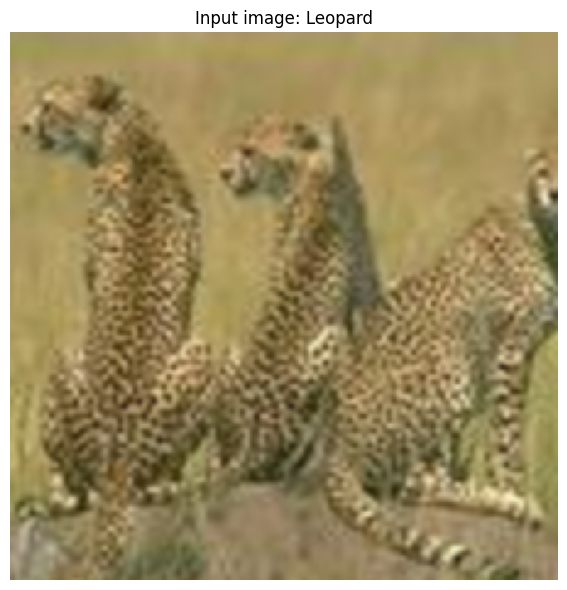

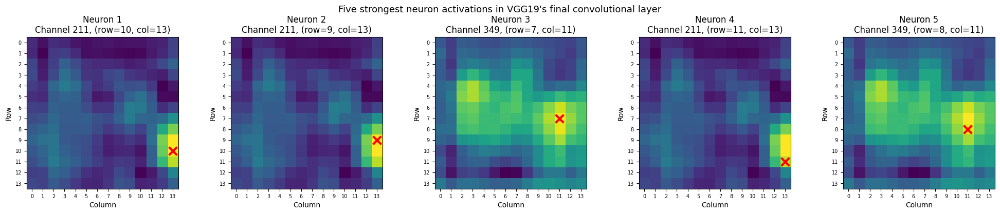

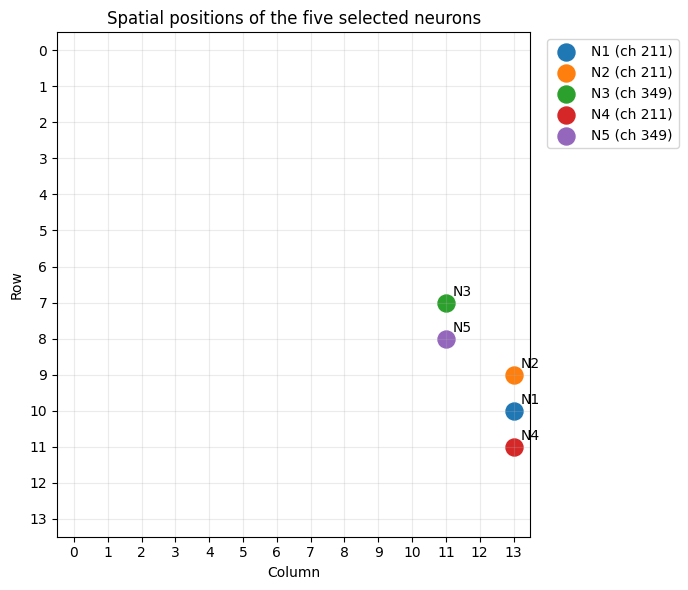

Saved visualizations to: /kaggle/working/part_b_q1_results


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the activation already captured by your forward hook.
activation = captured["activation"].detach()

print("Final convolution activation shape:", tuple(activation.shape))
# Expected: (1, 512, 14, 14)

# Find the five strongest individual neuron activations.
flat = activation[0].flatten()
top_values, top_indices = torch.topk(flat, k=5)

selected_neurons = []
height, width = activation.shape[-2:]

for rank, (value, index) in enumerate(
    zip(top_values, top_indices), start=1
):
    channel, spatial_index = divmod(int(index.item()), height * width)
    row, col = divmod(spatial_index, width)

    selected_neurons.append({
        "rank": rank,
        "channel": channel,
        "row": row,
        "col": col,
        "activation": float(value.item())
    })

neuron_df = pd.DataFrame(selected_neurons)

# Display the positions directly in the notebook.
display(
    neuron_df.style
    .format({"activation": "{:.4f}"})
    .set_caption("Five selected neurons in VGG19's final convolutional layer")
)

# Save the positions for reproducibility.
neuron_df.to_csv(
    OUTPUT_DIR / "q2c_vgg19_selected_neurons.csv",
    index=False
)

# ---------------------------------------------------------
# Figure 1: Original input image
# ---------------------------------------------------------
# Reconstruct the image from the tensor using the same
# ImageNet normalization used by the pretrained VGG19 weights.
mean = torch.tensor(
    weights.transforms().mean, device=input_tensor.device
).view(1, 3, 1, 1)

std = torch.tensor(
    weights.transforms().std, device=input_tensor.device
).view(1, 3, 1, 1)

display_tensor = (input_tensor.detach() * std + mean).clamp(0, 1)
display_image = display_tensor[0].permute(1, 2, 0).cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(display_image)
ax.set_title("Input image: Leopard")
ax.axis("off")
plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "q2c_input_leopard.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------------------
# Figure 2: The five selected neuron locations
# ---------------------------------------------------------
# Show the activation map for each selected channel.
# A red marker identifies the selected (row, column).
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, neuron in zip(axes, selected_neurons):
    ch = neuron["channel"]
    r = neuron["row"]
    c = neuron["col"]

    feature_map = activation[0, ch].cpu().numpy()

    ax.imshow(feature_map, cmap="viridis")
    ax.scatter(
        c, r,
        s=130,
        marker="x",
        linewidths=3,
        color="red"
    )
    ax.set_title(
        f"Neuron {neuron['rank']}\n"
        f"Channel {ch}, (row={r}, col={c})"
    )
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_xticks(range(width))
    ax.set_yticks(range(height))
    ax.tick_params(labelsize=7)

fig.suptitle(
    "Five strongest neuron activations in VGG19's final convolutional layer",
    fontsize=13
)
plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "q2c_vgg19_selected_neuron_positions_my_style.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ---------------------------------------------------------
# Figure 3: Spatial positions together on the feature map
# ---------------------------------------------------------
# Each point is a selected neuron. Neurons may share a channel
# but occupy different spatial positions.
fig, ax = plt.subplots(figsize=(7, 6))
ax.set_xlim(-0.5, width - 0.5)
ax.set_ylim(height - 0.5, -0.5)
ax.set_xticks(range(width))
ax.set_yticks(range(height))
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title("Spatial positions of the five selected neurons")
ax.grid(True, alpha=0.25)

for neuron in selected_neurons:
    ax.scatter(
        neuron["col"], neuron["row"],
        s=150,
        label=f"N{neuron['rank']} (ch {neuron['channel']})"
    )
    ax.annotate(
        f"N{neuron['rank']}",
        (neuron["col"], neuron["row"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "q2c_vgg19_spatial_positions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Saved visualizations to:", OUTPUT_DIR)

Neuron 1: channel=211, row=10, col=13, activation=8.99912, max_abs_gradient=5.249500e+00
Neuron 2: channel=211, row=9, col=13, activation=8.94698, max_abs_gradient=4.824580e+00
Neuron 3: channel=349, row=7, col=11, activation=8.20477, max_abs_gradient=2.622982e+00
Neuron 4: channel=211, row=11, col=13, activation=7.70105, max_abs_gradient=4.110458e+00
Neuron 5: channel=349, row=8, col=11, activation=7.68201, max_abs_gradient=2.632507e+00


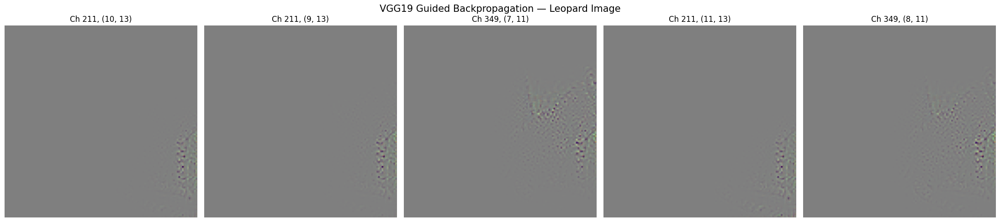

Saved five-neuron visualization: /kaggle/working/part_b_q1_results/q2c_vgg19_guided_backpropagation.png
All five individual gradient images have been saved.


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 1. Confirm the input and selected neurons are available
# ---------------------------------------------------------
assert "selected_neurons" in globals(), (
    "Run the neuron-selection and visualization cell first."
)
assert "input_tensor" in globals(), "The input image tensor is missing."

# Ensure input gradients can be calculated.
input_tensor = input_tensor.detach().clone().to(device)
input_tensor.requires_grad_(True)

# ---------------------------------------------------------
# 2. Implement guided backpropagation
# ---------------------------------------------------------
# Standard ReLU backward:
#   gradient * (forward activation > 0)
#
# Guided ReLU backward:
#   max(gradient, 0) * (forward activation > 0)

relu_handles = []

def guided_relu_forward_hook(module, inputs, output):
    # Save which activations were positive during the forward pass.
    module.guided_positive_mask = (output > 0).detach()

def guided_relu_backward_hook(module, grad_input, grad_output):
    if not grad_input or grad_input[0] is None:
        return None

    incoming_gradient = grad_output[0]

    if incoming_gradient is None:
        return None

    positive_gradient = torch.clamp(incoming_gradient, min=0)
    positive_mask = module.guided_positive_mask

    guided_gradient = positive_gradient * positive_mask.to(
        dtype=positive_gradient.dtype
    )

    return (guided_gradient,)

# Remove old guided-backprop hooks if this cell is rerun.
for handle in globals().get("guided_relu_handles", []):
    handle.remove()

guided_relu_handles = []

for layer in vgg_model.modules():
    if isinstance(layer, nn.ReLU):
        guided_relu_handles.append(
            layer.register_forward_hook(guided_relu_forward_hook)
        )
        guided_relu_handles.append(
            layer.register_full_backward_hook(guided_relu_backward_hook)
        )

# ---------------------------------------------------------
# 3. Capture the last convolutional layer
# ---------------------------------------------------------
last_conv_activations = {}

def capture_last_conv(module, inputs, output):
    last_conv_activations["activation"] = output

conv_handle = vgg_model.features[34].register_forward_hook(
    capture_last_conv
)

guided_images = []

try:
    for neuron in selected_neurons:
        vgg_model.zero_grad(set_to_none=True)

        if input_tensor.grad is not None:
            input_tensor.grad.zero_()

        last_conv_activations.clear()

        # Forward pass
        logits = vgg_model(input_tensor)

        conv_activation = last_conv_activations["activation"]

        channel = neuron["channel"]
        row = neuron["row"]
        col = neuron["col"]

        # Target the selected individual neuron, not the class logit.
        target_score = conv_activation[0, channel, row, col]

        # Backpropagate from this neuron to the input pixels.
        target_score.backward()

        input_gradient = input_tensor.grad.detach()[0]

        # Convert CHW gradients into HWC for visualization.
        gradient = (
            input_gradient.permute(1, 2, 0).cpu().numpy()
        )

        # Normalize each gradient image independently for display.
        scale = np.max(np.abs(gradient))
        if scale > 0:
            gradient_display = gradient / scale
        else:
            gradient_display = gradient

        guided_images.append(gradient_display.copy())

        print(
            f"Neuron {neuron['rank']}: "
            f"channel={channel}, row={row}, col={col}, "
            f"activation={neuron['activation']:.5f}, "
            f"max_abs_gradient={scale:.6e}"
        )

finally:
    conv_handle.remove()

    for handle in guided_relu_handles:
        handle.remove()

    guided_relu_handles = []

# ---------------------------------------------------------
# 4. Display all five gradient images
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, neuron, gradient in zip(
    axes, selected_neurons, guided_images
):
    # Neutral gray represents zero; positive/negative gradients
    # are displayed on opposite sides of gray.
    visualization = np.clip((gradient + 1) / 2, 0, 1)

    ax.imshow(visualization)
    ax.set_title(
        # f"Neuron {neuron['rank']}\n"
        f"Ch {neuron['channel']}, "
        f"({neuron['row']}, {neuron['col']})"
    )
    ax.axis("off")

fig.suptitle(
    "VGG19 Guided Backpropagation — Leopard Image",
    fontsize=15
)
plt.tight_layout()

output_path = OUTPUT_DIR / "q2c_vgg19_guided_backpropagation.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved five-neuron visualization:", output_path)

# ---------------------------------------------------------
# 5. Save each gradient image individually
# ---------------------------------------------------------
for neuron, gradient in zip(selected_neurons, guided_images):
    visualization = np.clip((gradient + 1) / 2, 0, 1)

    filename = (
        f"q2c_guided_backprop_neuron_{neuron['rank']}_"
        f"channel_{neuron['channel']}.png"
    )

    plt.imsave(OUTPUT_DIR / filename, visualization)

print("All five individual gradient images have been saved.")

# **Q2 d**

Grad-CAM target layer: Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Classes: ['Leopards', 'buddha', 'butterfly', 'kangaroo', 'starfish']
Output directory: /kaggle/working/part_b_q1_results/q2d_gradcam
Leopards: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train/Leopards/image_0004.jpg
buddha: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train/buddha/image_0001.jpg
butterfly: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train/butterfly/image_0001.jpg
kangaroo: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train/kangaroo/image_0002.jpg
starfish: /kaggle/input/datasets/aditya000001/group-16-caltech-101/Group_16/train/starfish/image_0002.jpg


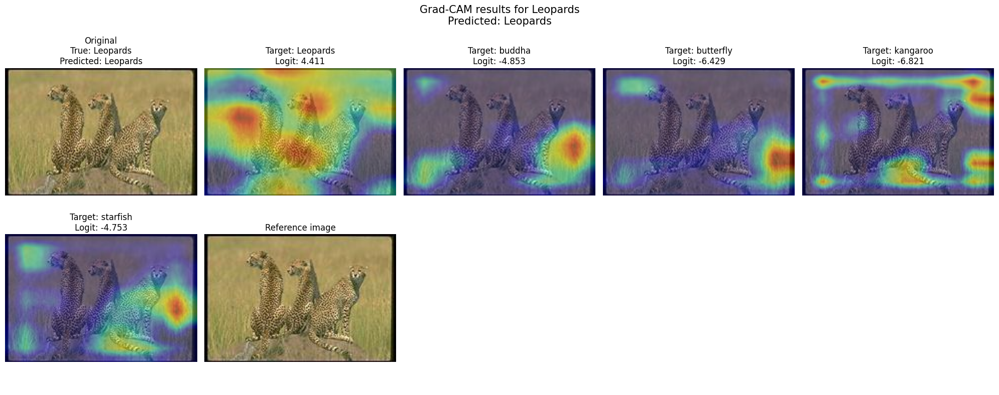

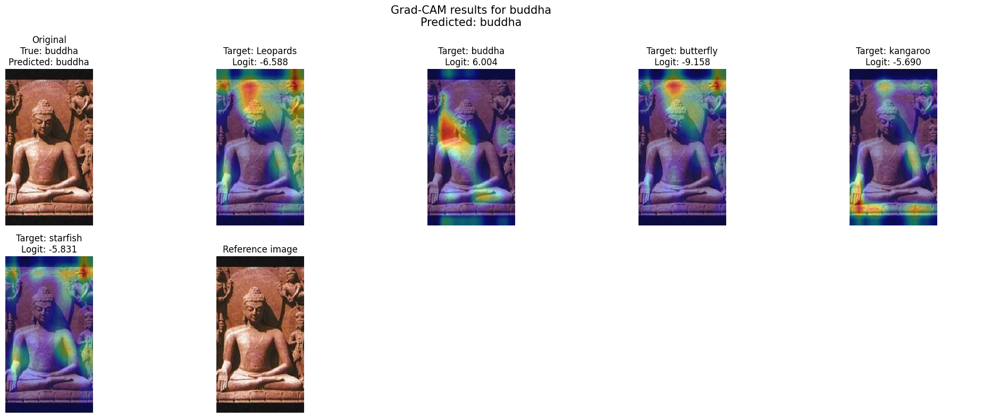

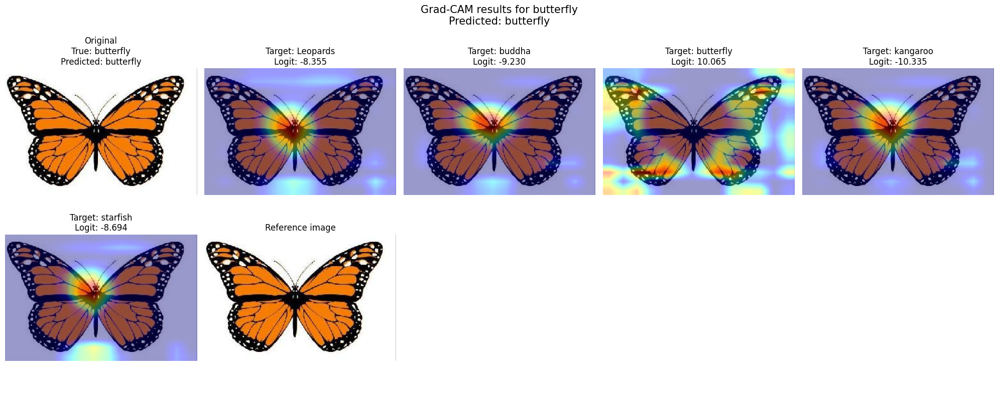

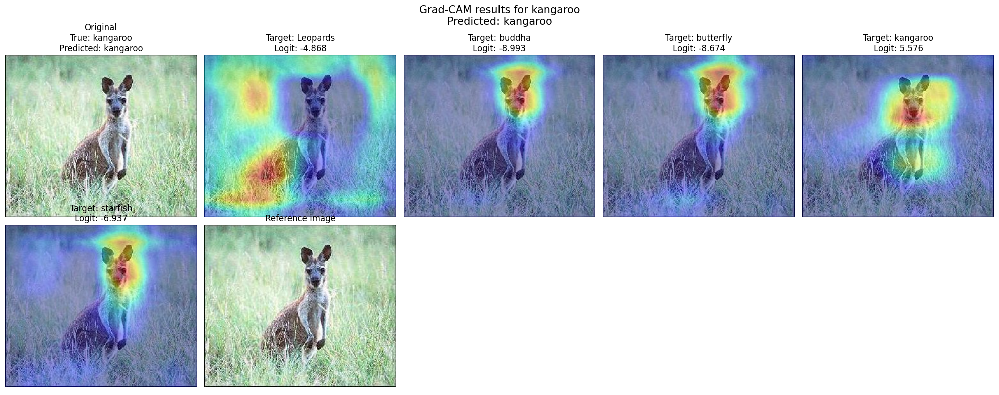

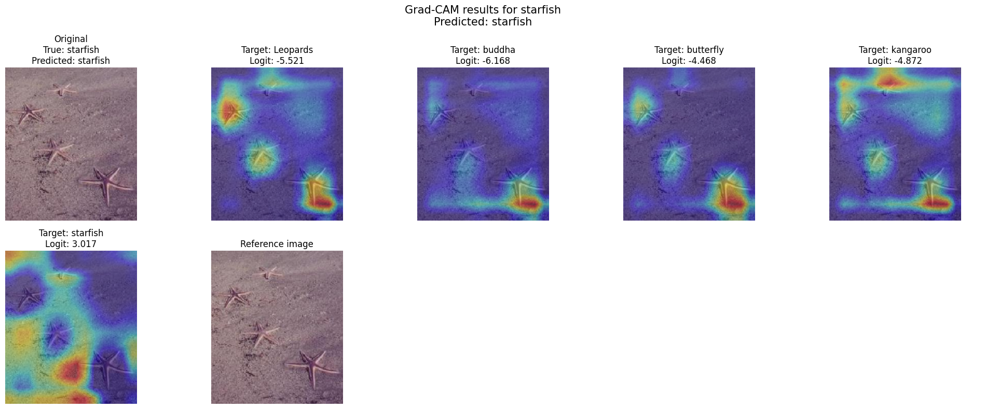


Completed!
Number of Grad-CAM maps: 25
Metadata CSV: /kaggle/working/part_b_q1_results/q2d_gradcam/q2d_gradcam_results.csv
Saved outputs to: /kaggle/working/part_b_q1_results/q2d_gradcam


,image_true_class,image_filename,predicted_class,target_class,target_class_index,target_logit,target_probability,heatmap_path,overlay_path
0,Leopards,image_0004.jpg,Leopards,Leopards,0,4.411105,9.997677e-01,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
1,Leopards,image_0004.jpg,Leopards,buddha,1,-4.852909,9.475210e-05,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
2,Leopards,image_0004.jpg,Leopards,butterfly,2,-6.428585,1.960116e-05,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
3,Leopards,image_0004.jpg,Leopards,kangaroo,3,-6.821208,1.323633e-05,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
4,Leopards,image_0004.jpg,Leopards,starfish,4,-4.752505,1.047596e-04,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
5,buddha,image_0001.jpg,buddha,Leopards,0,-6.587625,3.401456e-06,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
6,buddha,image_0001.jpg,buddha,buddha,1,6.003664,9.999807e-01,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
7,buddha,image_0001.jpg,buddha,butterfly,2,-9.157845,2.602748e-07,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
8,buddha,image_0001.jpg,buddha,kangaroo,3,-5.690494,8.342264e-06,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...
9,buddha,image_0001.jpg,buddha,starfish,4,-5.830960,7.249032e-06,/kaggle/working/part_b_q1_results/q2d_gradcam/...,/kaggle/working/part_b_q1_results/q2d_gradcam/...


In [17]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# ---------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------
DATA_ROOT = Path(
    "/kaggle/input/datasets/aditya000001/"
    "group-16-caltech-101/Group_16"
)

OUTPUT_DIR = Path("/kaggle/working/part_b_q1_results/q2d_gradcam")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the same five representative images from Q1(d).
representative_files = {
    "Leopards": "image_0004.jpg",
    "buddha": "image_0001.jpg",
    "butterfly": "image_0001.jpg",
    "kangaroo": "image_0002.jpg",
    "starfish": "image_0002.jpg",
}

# Use the exact class order corresponding to the model's output.
# Your ImageFolder class order was:
# ['Leopards', 'buddha', 'butterfly', 'kangaroo', 'starfish']
class_names = ["Leopards", "buddha", "butterfly", "kangaroo", "starfish"]

assert len(class_names) == 5
assert vgg_model.classifier[6].out_features == 5

device = next(vgg_model.parameters()).device
vgg_model.eval()

# VGG19's final convolution.
target_layer = vgg_model.features[34]

print("Grad-CAM target layer:", target_layer)
print("Classes:", class_names)
print("Output directory:", OUTPUT_DIR)


# ---------------------------------------------------------
# 2. Load the five representative images
# ---------------------------------------------------------
representative_images = {}

for true_class, filename in representative_files.items():
    image_path = DATA_ROOT / "train" / true_class / filename

    if not image_path.exists():
        raise FileNotFoundError(
            f"Could not find representative image: {image_path}"
        )

    pil_image = Image.open(image_path).convert("RGB")

    # Same VGG19 pretrained transformation used during training.
    image_tensor = vgg_transform(pil_image).unsqueeze(0).to(device)

    representative_images[true_class] = {
        "path": image_path,
        "pil": pil_image,
        "tensor": image_tensor,
    }

    print(f"{true_class}: {image_path}")


# ---------------------------------------------------------
# 3. Grad-CAM function for a specified target class
# ---------------------------------------------------------
def make_gradcam(input_tensor, target_class_index):
    """
    Generate a Grad-CAM heatmap for one target class.

    input_tensor: normalized image tensor, shape (1, 3, H, W)
    target_class_index: integer index of the target class

    Returns:
        heatmap: normalized 2D NumPy array in [0, 1]
        logits: model output logits
    """
    captured = {}

    def forward_hook(module, inputs, output):
        captured["features"] = output

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        vgg_model.zero_grad(set_to_none=True)

        # Gradients must remain enabled.
        with torch.enable_grad():
            x = input_tensor.detach().clone().requires_grad_(True)
            logits = vgg_model(x)

            conv_features = captured["features"]

            # Use the target class logit, not the predicted class every time.
            target_score = logits[0, target_class_index]

            gradients = torch.autograd.grad(
                outputs=target_score,
                inputs=conv_features,
                retain_graph=False,
                create_graph=False,
            )[0]

            # Global average pooling of gradients over spatial dimensions.
            channel_weights = gradients.mean(dim=(2, 3), keepdim=True)

            # Weighted sum of convolutional feature maps.
            cam = (channel_weights * conv_features).sum(dim=1, keepdim=True)

            # Keep positive evidence for the selected target class.
            cam = F.relu(cam)

            # Upsample to the transformed input's spatial dimensions.
            cam = F.interpolate(
                cam,
                size=x.shape[-2:],
                mode="bilinear",
                align_corners=False,
            )

            cam = cam[0, 0].detach().cpu().numpy()
            logits = logits.detach()

        # Normalize safely.
        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max > cam_min:
            heatmap = (cam - cam_min) / (cam_max - cam_min)
        else:
            heatmap = np.zeros_like(cam)

        return heatmap, logits

    finally:
        handle.remove()


# ---------------------------------------------------------
# 4. Create and save all 25 heatmaps and overlays
# ---------------------------------------------------------
records = []
all_results = {}

for true_class, item in representative_images.items():
    pil_image = item["pil"]
    input_tensor = item["tensor"]

    # Model's predicted class for this image.
    with torch.no_grad():
        logits = vgg_model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]

    # Convert original image to RGB array for overlay visualization.
    # Use the original image size, not the normalized tensor.
    original_image = np.asarray(pil_image.convert("RGB"))

    # Grad-CAM heatmaps are resized to the transformed input size.
    # Then resized to the original image's dimensions for overlays.
    image_height, image_width = original_image.shape[:2]

    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.ravel()

    # First panel: original image and prediction.
    axes[0].imshow(original_image)
    axes[0].set_title(
        f"Original\nTrue: {true_class}\nPredicted: {predicted_class}"
    )
    axes[0].axis("off")

    # Remaining five panels: one per target class.
    result_for_image = {}

    for target_index, target_class in enumerate(class_names):
        heatmap, class_logits = make_gradcam(
            input_tensor,
            target_class_index=target_index,
        )

        # Resize heatmap to original photograph dimensions.
        heatmap_image = Image.fromarray(
            np.uint8(np.clip(heatmap, 0, 1) * 255)
        ).resize(
            (image_width, image_height),
            resample=Image.Resampling.BILINEAR,
        )

        heatmap_full = np.asarray(heatmap_image).astype(np.float32) / 255.0

        # Save the standalone heatmap.
        heatmap_path = OUTPUT_DIR / (
            f"{true_class}_target_{target_class}_heatmap.png"
        )
        plt.imsave(heatmap_path, heatmap_full, cmap="jet", vmin=0, vmax=1)

        # Overlay heatmap on the original image.
        fig_overlay, ax_overlay = plt.subplots(figsize=(6, 6))
        ax_overlay.imshow(original_image)
        ax_overlay.imshow(
            heatmap_full,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1,
        )
        ax_overlay.set_title(
            f"True: {true_class} | Target: {target_class}"
        )
        ax_overlay.axis("off")

        overlay_path = OUTPUT_DIR / (
            f"{true_class}_target_{target_class}_overlay.png"
        )
        fig_overlay.savefig(
            overlay_path,
            dpi=160,
            bbox_inches="tight",
            pad_inches=0.05,
        )
        plt.close(fig_overlay)

        # Place overlays in the overview grid.
        # axes[0] is original, so the first five maps occupy axes[1:6].
        axes[target_index + 1].imshow(original_image)
        axes[target_index + 1].imshow(
            heatmap_full,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1,
        )
        axes[target_index + 1].set_title(
            f"Target: {target_class}\n"
            f"Logit: {class_logits[0, target_index].item():.3f}"
        )
        axes[target_index + 1].axis("off")

        result_for_image[target_class] = {
            "heatmap": heatmap_full,
            "heatmap_path": str(heatmap_path),
            "overlay_path": str(overlay_path),
        }

        records.append({
            "image_true_class": true_class,
            "image_filename": item["path"].name,
            "predicted_class": predicted_class,
            "target_class": target_class,
            "target_class_index": target_index,
            "target_logit": float(class_logits[0, target_index].item()),
            "target_probability": float(probabilities[target_index]),
            "heatmap_path": str(heatmap_path),
            "overlay_path": str(overlay_path),
        })

    # The 2x5 grid has one original plus five maps; remaining four
    # axes are intentionally used for an extra large original/map view
    # and left blank to keep a consistent 2x5 report layout.
    axes[6].imshow(original_image)
    axes[6].set_title("Reference image")
    axes[6].axis("off")

    for idx in range(7, 10):
        axes[idx].axis("off")

    fig.suptitle(
        f"Grad-CAM results for {true_class}\n"
        f"Predicted: {predicted_class}",
        fontsize=15,
    )
    plt.tight_layout()

    overview_path = OUTPUT_DIR / f"{true_class}_gradcam_overview.png"
    fig.savefig(overview_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    all_results[true_class] = result_for_image

# Save the metadata for all 25 image/class combinations.
results_df = pd.DataFrame(records)
csv_path = OUTPUT_DIR / "q2d_gradcam_results.csv"
results_df.to_csv(csv_path, index=False)

print("\nCompleted!")
print("Number of Grad-CAM maps:", len(records))
print("Metadata CSV:", csv_path)
print("Saved outputs to:", OUTPUT_DIR)
display(results_df)

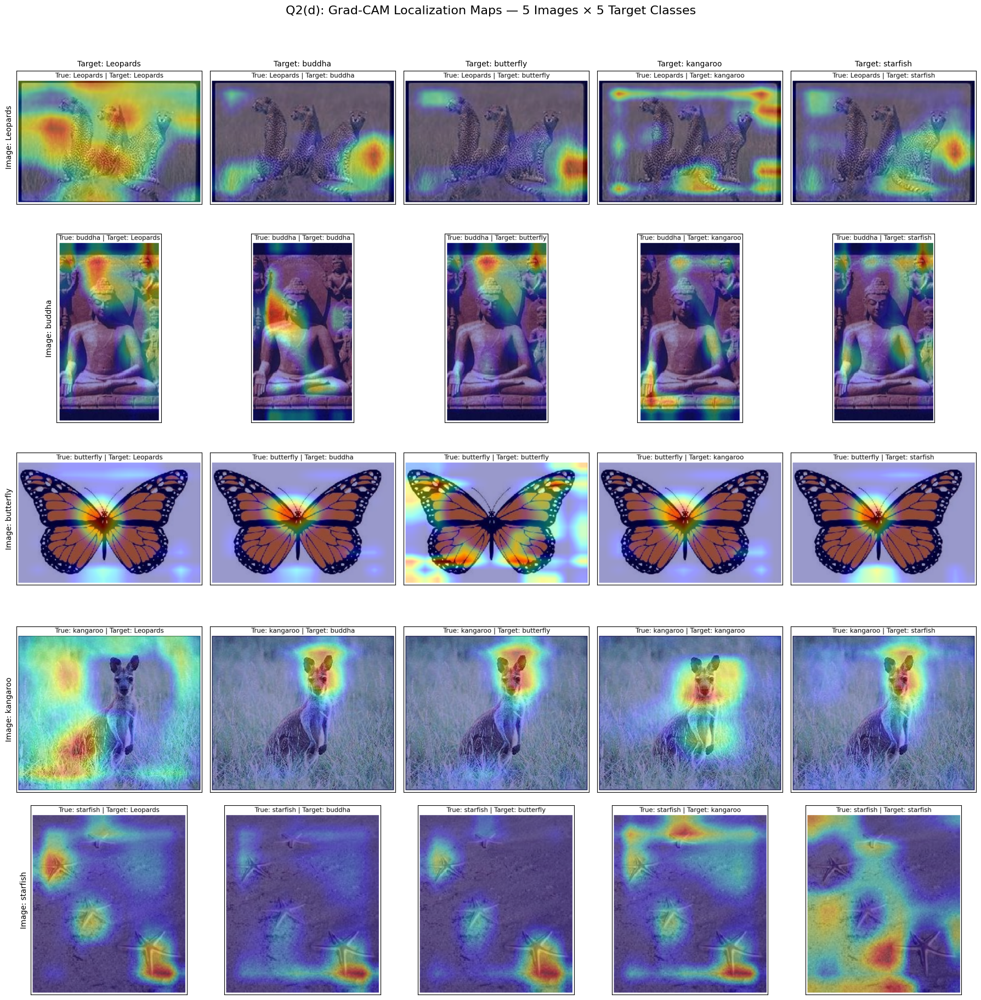

Final 25-map report figure: /kaggle/working/part_b_q1_results/q2d_gradcam/q2d_gradcam_all_25_maps.png


In [18]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(5, 5, figsize=(18, 18))

for row, true_class in enumerate(class_names):
    for col, target_class in enumerate(class_names):
        result = all_results[true_class][target_class]
        overlay_path = result["overlay_path"]

        overlay = Image.open(overlay_path).convert("RGB")
        axes[row, col].imshow(overlay)

        if row == 0:
            axes[row, col].set_title(
                f"Target: {target_class}", fontsize=10
            )

        if col == 0:
            axes[row, col].set_ylabel(
                f"Image: {true_class}", fontsize=10
            )

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

fig.suptitle(
    "Q2(d): Grad-CAM Localization Maps — 5 Images × 5 Target Classes",
    fontsize=16,
    y=1.01,
)
plt.tight_layout()

grid_path = OUTPUT_DIR / "q2d_gradcam_all_25_maps.png"
fig.savefig(grid_path, dpi=200, bbox_inches="tight")
plt.show()

print("Final 25-map report figure:", grid_path)

In [19]:
!zip -r taskB_Q2_d.zip /kaggle/working/part_b_q1_results/q2d_gradcam

  adding: kaggle/working/part_b_q1_results/q2d_gradcam/ (stored 0%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/butterfly_target_butterfly_heatmap.png (deflated 0%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/Leopards_target_kangaroo_overlay.png (deflated 6%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/starfish_target_starfish_heatmap.png (deflated 0%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/kangaroo_target_butterfly_heatmap.png (deflated 1%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/butterfly_target_starfish_heatmap.png (deflated 1%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/q2d_gradcam_all_25_maps.png (deflated 1%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/kangaroo_target_Leopards_overlay.png (deflated 0%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/buddha_target_buddha_heatmap.png (deflated 0%)
  adding: kaggle/working/part_b_q1_results/q2d_gradcam/Leopards_gradcam_overview.png (deflate